# 05 · Tendência, sazonalidade e ciclo

**Objetivo:** caracterizar a estrutura temporal das séries **antes da modelagem** e transformar cada diagnóstico em uma decisão para os modelos do notebook 06. O notebook responde a quatro perguntas:
1. **Tendência:** o crescimento é uma tendência determinística ou uma sequência de degraus de nível?
2. **Sazonalidade:** quais periodicidades existem? A ferramenta é o **periodograma com o teste g exato de Fisher**, a mesma metodologia de `teste.ipynb`.
3. **Ciclo:** há oscilações mais longas que a semana e sem período fixo?
4. **Autocorrelação:** como ficam a ACF e a PACF **antes e depois de remover a tendência pela diferença**? A série é estacionária?

| Diagnóstico | Métodos | Decisão que informa |
|---|---|---|
| Tendência | Mann-Kendall com correção de Hamed-Rao; regressões linear × degraus (AIC/BIC, erro HAC) | `d` do SARIMA, tendência no ETS, dummies de regime |
| Sazonalidade | periodograma + g de Fisher iterativo; faixa fixada a priori; F do dia da semana por regime | período sazonal, janela de estimação |
| Ciclo | STL + nível do regime + filtro HP; Fisher na escala semanal; Ljung-Box; dia do mês | atributos de ciclo e de início do mês |
| Autocorrelação | ACF/PACF de y, Δ1, Δ7 e Δ1Δ7; ADF, KPSS, Zivot-Andrews | ordens (p, d, q)(P, D, Q)₇ |

**Escopo e cuidados:**
- **Só o treino da origem principal** (até 09/03/2025). Nenhuma escolha usa a janela de teste.
- Séries: **Máquina 1** e **Total**. A Máquina 2 tem 30 dias de treino. Com isso, o periodograma teria resolução de 1/30 ciclo por dia e só 4 semanas, e a banda de significância da ACF seria de ±0,36: os testes não teriam poder. O tratamento dela fica no notebook 06.
- Regimes: as datas vêm do notebook 03 e foram detectadas só com o treino. São a ampliação do horário (18/05/2024) e as quebras de nível de 24/07/2024, 16/11/2024 e 30/01/2025 (M1) ou 04/02/2025 (Total).
- Código: `src/eda/trend_seasonality.py`, testado em `tests/test_trend_seasonality.py`.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import STL

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    if fig is not None:
        display(fig)
        plt.close(fig)

from src.data.preprocessing import preparar_base
from src.structural_breaks.structural_break_test import DetectorQuebras
from src.eda import trend_seasonality as ts
from src.visualization.plots import CORES, cor_serie, formatar_eixo_datas

base = preparar_base()
det = DetectorQuebras(base.series, base.transacoes)
ORIGEM = pd.Timestamp("2025-03-09")      # último dia do treino da origem principal
SERIES = ["Máquina 1", "Total"]
ALVOS = ["demanda", "receita"]
UNIDADE = {"demanda": "transações/dia", "receita": "unidades monetárias/dia"}

Y = {(s, a): base.series[(s, a)].loc[:ORIGEM] for s in SERIES for a in ALVOS}
QUEBRAS = {s: [det.janela_ate(s, ORIGEM)] + det.quebras_ate(s, ORIGEM) for s in SERIES}
ROTULOS = {s: {"horário ampliado": QUEBRAS[s][0], **{f"{q:%d/%m/%y}": q for q in QUEBRAS[s][1:]}} for s in SERIES}
for s in SERIES:
    y = Y[(s, "demanda")]
    print(f"{s}: {y.index.min():%d/%m/%Y} a {y.index.max():%d/%m/%Y} ({len(y)} dias) | "
          f"novos regimes em {', '.join(f'{q:%d/%m/%Y}' for q in QUEBRAS[s])}")

2026-11-10 19:10:35 | INFO    | src.data.load_data | Dados brutos conferidos com o MANIFEST.json (SHA-256)


2026-11-10 19:10:35 | INFO    | src.data.load_data | index_1.csv: 3636 registros válidos (máquina 1)


2026-11-10 19:10:35 | INFO    | src.data.load_data | index_2.csv: 262 registros válidos (máquina 2)


2026-11-10 19:10:35 | INFO    | src.data.preprocessing | Séries diárias construídas: {('Máquina 1', 'demanda'): 388, ('Máquina 1', 'receita'): 388, ('Máquina 2', 'demanda'): 44, ('Máquina 2', 'receita'): 44, ('Total', 'demanda'): 388, ('Total', 'receita'): 388}


Máquina 1: 01/03/2024 a 09/03/2025 (374 dias) | novos regimes em 18/05/2024, 24/07/2024, 16/11/2024, 30/01/2025
Total: 01/03/2024 a 09/03/2025 (374 dias) | novos regimes em 18/05/2024, 24/07/2024, 16/11/2024, 04/02/2025


## 1. Visão geral: decomposição STL e força dos componentes

A STL robusta, com período de 7 dias, separa a série em tendência-ciclo, sazonal e resíduo. A **força** de cada componente (Wang, Smith e Hyndman, 2006) é F = max(0, 1 − Var(R) / Var(C + R)). Valores perto de 0 indicam que o componente não se destaca do ruído; perto de 1, que domina a variação.

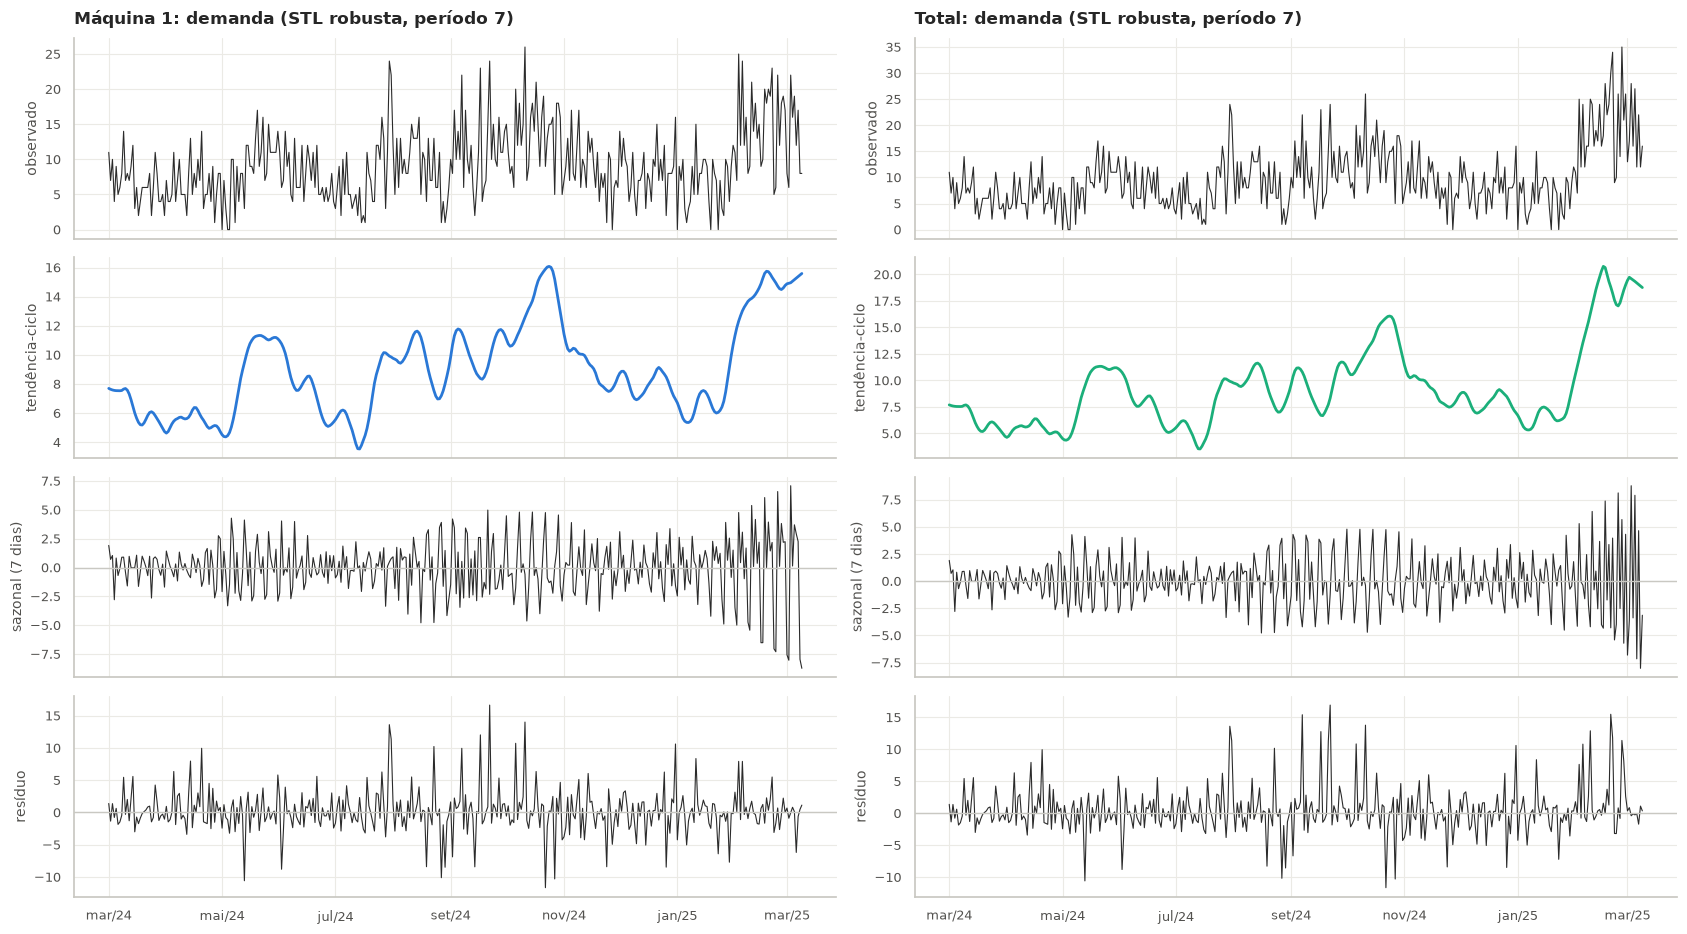

,série,alvo,força da tendência,força da sazonalidade
0,Máquina 1,demanda,0.466,0.277
1,Máquina 1,receita,0.449,0.274
2,Total,demanda,0.561,0.219
3,Total,receita,0.534,0.224


In [2]:
fig, eixos = plt.subplots(4, 2, figsize=(17, 9.5), sharex=True)
for j, s in enumerate(SERIES):
    y = Y[(s, "demanda")].astype(float)
    r = STL(y, period=7, robust=True).fit()
    for i, (comp, rot) in enumerate([(y, "observado"), (r.trend, "tendência-ciclo"), (r.seasonal, "sazonal (7 dias)"), (r.resid, "resíduo")]):
        ax = eixos[i, j]
        ax.plot(comp.index, comp.values, color=cor_serie(s) if i == 1 else CORES["observado"], lw=2 if i == 1 else 0.8)
        if i > 1:
            ax.axhline(0, color=CORES["eixo"], lw=1)
        ax.set_ylabel(rot)
    eixos[0, j].set_title(f"{s}: demanda (STL robusta, período 7)")
    formatar_eixo_datas(eixos[3, j])
fig.tight_layout()
mostrar(fig)
display(pd.DataFrame([{"série": s, "alvo": a, **ts.forca_componentes(Y[(s, a)])} for s in SERIES for a in ALVOS]).round(3))

**Leitura:**
- A **tendência-ciclo não sobe de forma contínua.** Ela alterna patamares com ondulações de algumas semanas, o primeiro indício de degraus, e não de tendência linear:
  - ≈ 5–6 transações/dia em mar–mai/24;
  - ≈ 11 em ago–out/24;
  - ≈ 7–8 em dez/24–jan/25;
  - ≈ 15 (M1) e ≈ 20 (Total) em fev–mar/25.
- No ano inteiro, a **força da tendência é moderada** (0,45 a 0,56) e a da **sazonalidade é fraca** (0,22 a 0,28). No entanto, a amplitude do componente sazonal **cresce visivelmente em 2025**: o padrão semanal não é estável ao longo do ano (seção 3.4).
- O resíduo tem picos isolados, os dias atípicos que o notebook 02 decidiu manter.

## 2. Tendência

**Duas hipóteses concorrentes:**
- **H_T, tendência determinística:** o nível cresce de forma contínua no tempo.
- **H_D, degraus:** o nível é constante dentro de cada regime e muda nas quebras (horário, clientela, Máquina 2).

As duas produzem um Mann-Kendall significativo na série inteira. O que as separa é (a) o teste **dentro** de cada regime e (b) a comparação de modelos por AIC/BIC.

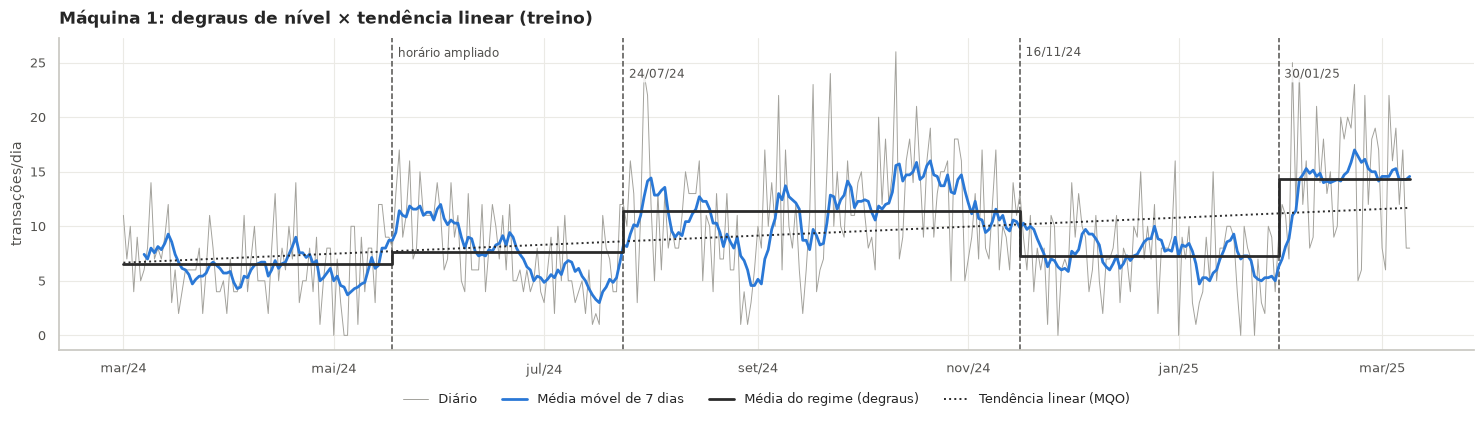

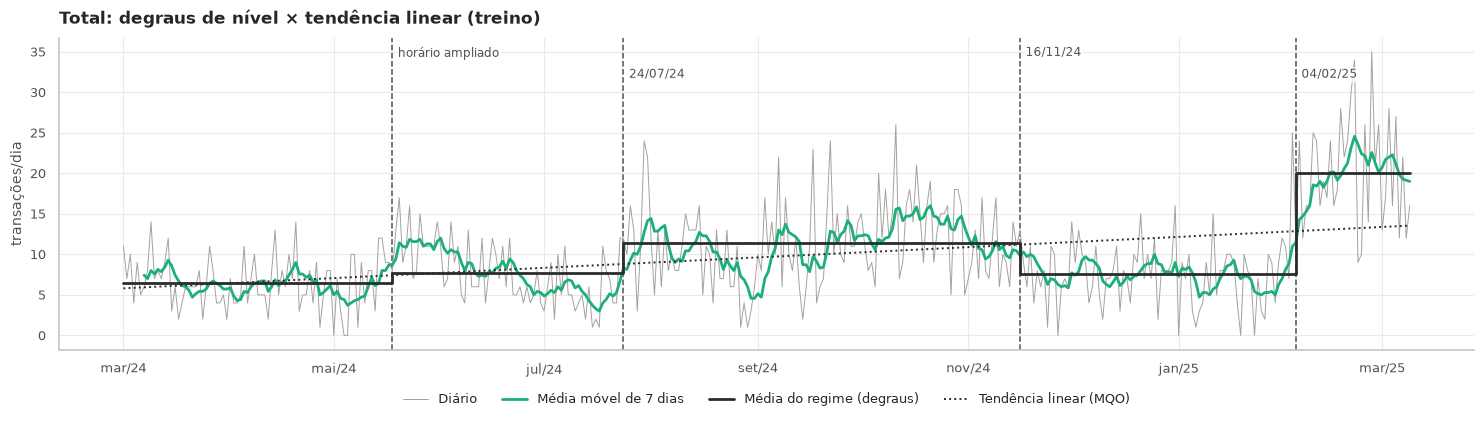

In [3]:
for s in SERIES:
    mostrar(ts.grafico_tendencia(Y[(s, "demanda")], ROTULOS[s], s, UNIDADE["demanda"]))

### 2.1 Mann-Kendall com correção de Hamed-Rao (médias semanais)

As médias semanais retiram o ciclo de 7 dias. A correção de Hamed-Rao ajusta a variância da estatística à autocorrelação; sem ela, o teste rejeita a ausência de tendência com frequência excessiva em séries persistentes.

In [4]:
for s in SERIES:
    display(Markdown(f"**{s} — demanda**"))
    display(ts.testes_mann_kendall(Y[(s, "demanda")], QUEBRAS[s]).round(3))

**Máquina 1 — demanda**

,trecho,semanas,tau de Kendall,Sen (por semana),Sen (% da média por semana),p (Hamed-Rao),tendência
0,série inteira,53,0.290,0.097,1.052,0.034,crescente
1,regime 1: 01/03/24–17/05/24,11,0.073,0.054,0.825,0.815,não significativa
2,regime 2: 18/05/24–23/07/24,9,-0.833,-0.893,-11.768,0.002,decrescente
3,regime 3: 24/07/24–15/11/24,17,0.191,0.156,1.381,0.303,não significativa
4,regime 4: 16/11/24–29/01/25,10,-0.356,-0.143,-2.000,0.178,não significativa
5,regime 5: 30/01/25–09/03/25,6,0.267,0.143,1.029,0.566,não significativa


**Total — demanda**

,trecho,semanas,tau de Kendall,Sen (por semana),Sen (% da média por semana),p (Hamed-Rao),tendência
0,série inteira,53,0.298,0.121,1.249,0.032,crescente
1,regime 1: 01/03/24–17/05/24,11,0.073,0.054,0.825,0.815,não significativa
2,regime 2: 18/05/24–23/07/24,9,-0.833,-0.893,-11.768,0.002,decrescente
3,regime 3: 24/07/24–15/11/24,17,0.191,0.156,1.381,0.303,não significativa
4,regime 4: 16/11/24–03/02/25,11,-0.127,-0.048,-0.652,0.638,não significativa
5,regime 5: 04/02/25–09/03/25,5,NaN,NaN,NaN,NaN,— (poucas semanas)


### 2.2 Qual forma de tendência? Regressão de log(1 + y) com dia da semana

A inclinação é expressa em % por semana, e o p-valor usa erro-padrão HAC (Newey-West, 7 defasagens).

In [5]:
cols = ["modelo", "parâmetros", "AIC", "BIC", "ΔAIC", "ΔBIC", "R²", "inclinação (% por semana)", "p da inclinação (HAC)",
        "regimes com inclinação significativa (5%)"]
for s in SERIES:
    for a in ALVOS:
        display(Markdown(f"**{s} — {a}**"))
        display(ts.comparar_formas_tendencia(Y[(s, a)], QUEBRAS[s])[cols].round(3))

**Máquina 1 — demanda**

,modelo,parâmetros,AIC,BIC,ΔAIC,ΔBIC,R²,inclinação (% por semana),p da inclinação (HAC),regimes com inclinação significativa (5%)
0,sem tendência,7,679.349,706.819,96.917,62.893,0.028,NaN,NaN,NaN
1,linear,8,661.828,693.222,79.395,49.297,0.078,0.865,0.006,NaN
2,degraus (quebras),11,600.758,643.925,18.326,0.000,0.229,NaN,NaN,NaN
3,degraus + linear,12,599.892,646.983,17.460,3.058,0.235,-1.282,0.175,NaN
4,degraus + linear por regime,16,582.432,645.220,0.000,1.295,0.285,NaN,NaN,1 de 5


**Máquina 1 — receita**

,modelo,parâmetros,AIC,BIC,ΔAIC,ΔBIC,R²,inclinação (% por semana),p da inclinação (HAC),regimes com inclinação significativa (5%)
0,sem tendência,7,"1,039.861","1,067.331",54.499,21.454,0.032,NaN,NaN,NaN
1,linear,8,"1,036.220","1,067.614",50.858,21.738,0.046,0.759,0.137,NaN
2,degraus (quebras),11,"1,002.710","1,045.877",17.348,0.000,0.142,NaN,NaN,NaN
3,degraus + linear,12,"1,001.885","1,048.976",16.522,3.099,0.148,-2.169,0.199,NaN
4,degraus + linear por regime,16,985.362,"1,048.150",0.000,2.274,0.202,NaN,NaN,2 de 5


**Total — demanda**

,modelo,parâmetros,AIC,BIC,ΔAIC,ΔBIC,R²,inclinação (% por semana),p da inclinação (HAC),regimes com inclinação significativa (5%)
0,sem tendência,7,716.286,743.756,127.153,96.214,0.019,NaN,NaN,NaN
1,linear,8,685.773,717.167,96.640,69.625,0.101,1.164,0.002,NaN
2,degraus (quebras),11,604.375,647.542,15.242,0.000,0.288,NaN,NaN,NaN
3,degraus + linear,12,604.936,652.027,15.803,4.485,0.291,-0.904,0.355,NaN
4,degraus + linear por regime,16,589.133,651.921,0.000,4.379,0.334,NaN,NaN,1 de 5


**Total — receita**

,modelo,parâmetros,AIC,BIC,ΔAIC,ΔBIC,R²,inclinação (% por semana),p da inclinação (HAC),regimes com inclinação significativa (5%)
0,sem tendência,7,"1,055.019","1,082.489",63.295,33.972,0.026,NaN,NaN,NaN
1,linear,8,"1,046.757","1,078.152",55.034,29.635,0.053,1.043,0.066,NaN
2,degraus (quebras),11,"1,005.350","1,048.517",13.626,0.000,0.166,NaN,NaN,NaN
3,degraus + linear,12,"1,005.727","1,052.818",14.003,4.301,0.169,-1.635,0.335,NaN
4,degraus + linear por regime,16,991.724,"1,054.512",0.000,5.995,0.217,NaN,NaN,2 de 5


In [6]:
for s in SERIES:
    display(Markdown(f"**{s} — demanda: inclinação dentro de cada regime**"))
    display(ts.inclinacoes_por_regime(Y[(s, "demanda")], QUEBRAS[s]).round(3))

**Máquina 1 — demanda: inclinação dentro de cada regime**

,regime,dias,média diária,inclinação (% por semana),IC 95% inf.,IC 95% sup.,p (HAC),variação implícita no regime (%)
0,1: 01/03/24–17/05/24,78,6.500,-2.870,-7.915,2.452,0.285,-27.407
1,2: 18/05/24–23/07/24,67,7.687,-9.809,-13.377,-6.093,0.000,-62.219
2,3: 24/07/24–15/11/24,115,11.357,1.493,-0.673,3.707,0.178,27.300
3,4: 16/11/24–29/01/25,75,7.267,-3.016,-7.142,1.293,0.167,-27.657
4,5: 30/01/25–09/03/25,39,14.359,0.892,-1.253,3.083,0.418,4.937


**Total — demanda: inclinação dentro de cada regime**

,regime,dias,média diária,inclinação (% por semana),IC 95% inf.,IC 95% sup.,p (HAC),variação implícita no regime (%)
0,1: 01/03/24–17/05/24,78,6.500,-2.870,-7.915,2.452,0.285,-27.407
1,2: 18/05/24–23/07/24,67,7.687,-9.809,-13.377,-6.093,0.000,-62.219
2,3: 24/07/24–15/11/24,115,11.357,1.493,-0.673,3.707,0.178,27.300
3,4: 16/11/24–03/02/25,80,7.612,-0.818,-5.488,4.083,0.739,-8.848
4,5: 04/02/25–09/03/25,34,20.029,1.021,-3.823,6.109,0.685,4.906


**Leitura:**
- **Na série inteira, há "tendência" crescente.** O Mann-Kendall dá p ≈ 0,03 (Sen ≈ +1% por semana), e a reta dá +0,9% por semana na M1 e +1,2% no Total (p HAC < 0,01).
- **Dentro dos regimes, ela desaparece.** Em 4 dos 5 regimes, a inclinação não é significativa (p de 0,17 a 0,82).
  - A exceção é o regime 2 (18/05–23/07/2024), que **cai** ≈ 10% por semana entre a ampliação do horário e a quebra de julho.
  - Com um único ano de histórico, não dá para separar um efeito sazonal anual (meio do ano) de um declínio local (`docs/limitations.md`).
- **Os degraus vencem a reta com folga.**
  - O ΔBIC contra a tendência linear é de 49 na M1 e 70 no Total.
  - Somar t aos degraus **piora** o BIC (+3,1 e +4,5), e a inclinação fica negativa e não significativa (p = 0,18 e 0,35).
  - Na receita, o padrão se repete (ΔBIC de 22 a 30 contra a reta).
- O AIC prefere "degraus + inclinação por regime" por causa do regime 2. O BIC, que penaliza mais e é consistente, prefere os degraus puros.
- **Conclusão:** o crescimento de 2024–2025 é uma sucessão de **mudanças de patamar** (horário, clientela, Máquina 2), e não uma tendência determinística.
- **Para a modelagem:**
  - **não extrapolar tendência**: Holt-Winters sem componente de tendência, ETS(·,N,·), e nenhum termo t no SARIMAX ou no modelo de contagem;
  - representar o patamar por **dummies de regime** ou por um **nível que se adapta** (suavização exponencial, ou diferença com MA(1));
  - usar **janelas de estimação curtas**, que comecem depois da última quebra.

## 3. Sazonalidade: periodograma e teste g de Fisher

**Metodologia** (a mesma de `teste.ipynb`):
1. **Transformação.** Regride-se a amplitude (máx − mín) de cada janela de 7 dias contra a média da janela. Se a inclinação é positiva e significativa, a variância cresce com o nível e trabalha-se com log(1 + y).
2. **Tendência.** Retira-se um polinômio em t, de grau 5 na 1ª etapa e de grau 2 nas seguintes.
3. **Periodograma** dos resíduos nas frequências de Fourier λ_p = 2πp/T, com p = 1, …, [(T − 1)/2]: I(λ_p) = |Σ x_t e^{−iλ_p t}|² / T.
4. **Teste g de Fisher.** g = max I(λ_p) / Σ I(λ_p). H0 é ruído branco gaussiano, sem componente periódica. O p-valor é exato: P[g > z] = Σ_{j=1}^{a} (−1)^{j−1} C(n, j)(1 − jz)^{n−1}, com a = maior inteiro < 1/z.
5. **Período fundamental.** O pico pode ser um harmônico (3,5 dias = 7/2), e o período verdadeiro pode cair entre duas frequências da grade. Entre os períodos inteiros compatíveis com o pico, escolhe-se o de menor AIC da remoção do perfil.
6. **Iteração.** Se o pico é significativo, retira-se o perfil sazonal daquele período e volta-se ao passo 2. O processo para quando o maior pico deixa de ser significativo.

### 3.1 Transformação: amplitude × média

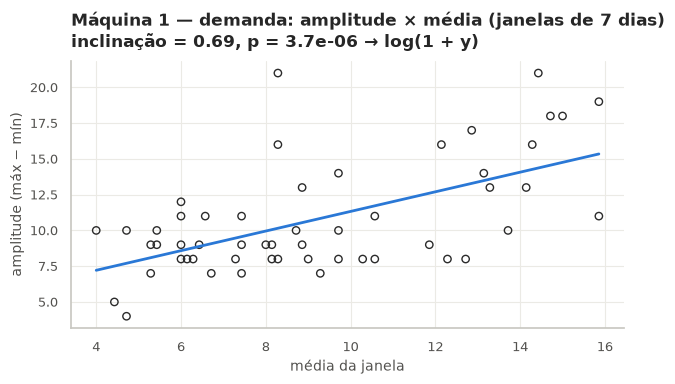

,série,alvo,inclinação amplitude × média,correlação,p,escala de trabalho
0,Máquina 1,demanda,0.686,0.588,0.000,log(1 + y)
1,Máquina 1,receita,0.632,0.572,0.000,log(1 + y)
2,Total,demanda,0.587,0.591,0.000,log(1 + y)
3,Total,receita,0.539,0.578,0.000,log(1 + y)


In [7]:
RES_FISHER = {(s, a): ts.metodologia_fisher(Y[(s, a)], f"{s} — {a}") for s in SERIES for a in ALVOS}
mostrar(ts.grafico_amplitude_media(RES_FISHER[("Máquina 1", "demanda")], cor_serie("Máquina 1")))
display(pd.DataFrame([{"série": s, "alvo": a, "inclinação amplitude × média": r.regressao_amplitude["inclinação"],
                       "correlação": r.regressao_amplitude["r"], "p": r.regressao_amplitude["p"],
                       "escala de trabalho": "log(1 + y)" if r.usar_log else "original"}
                      for (s, a), r in RES_FISHER.items()]))

### 3.2 Aplicação direta da metodologia ao treino inteiro

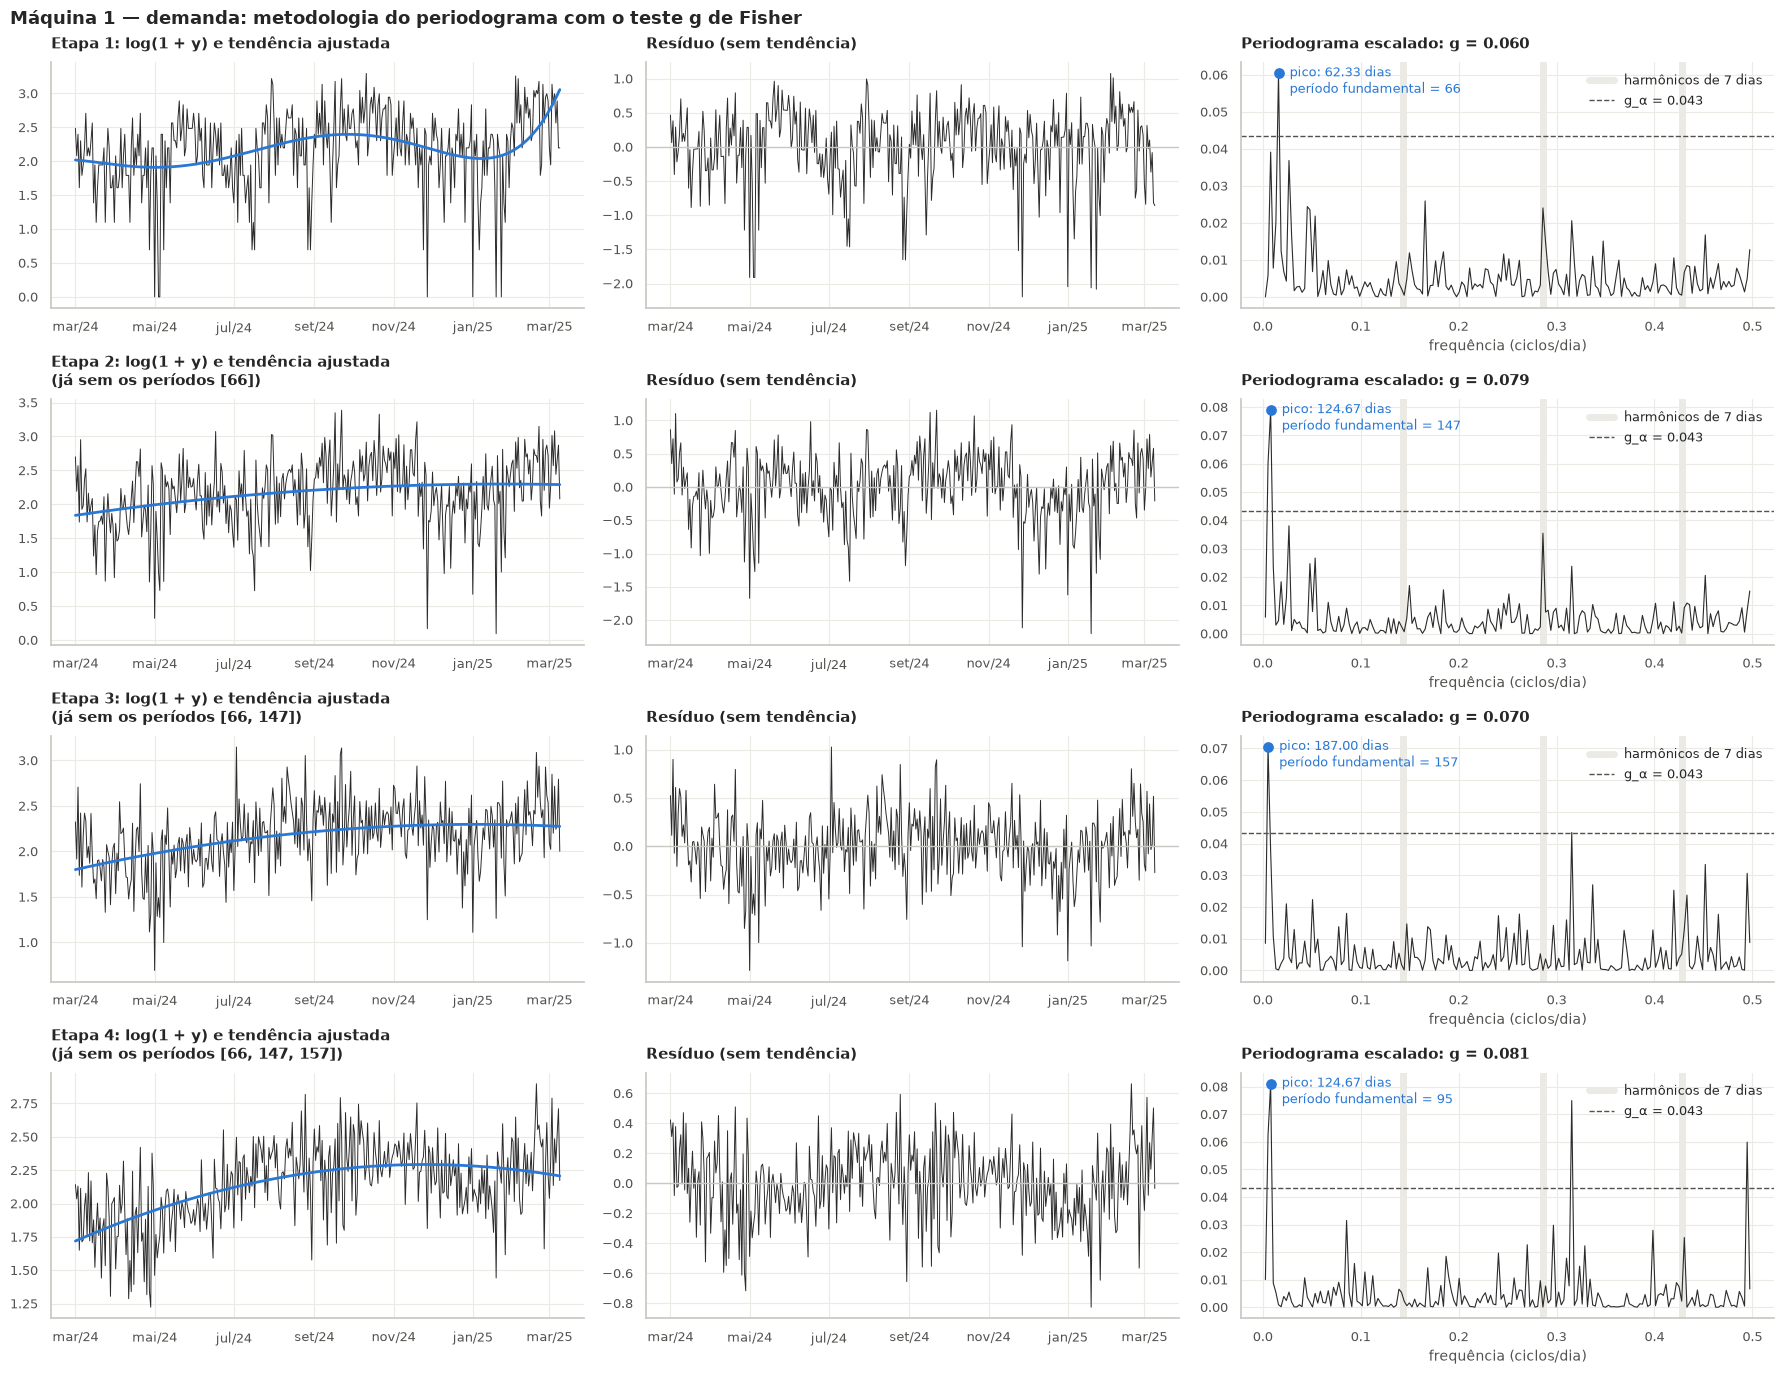

**Máquina 1 — demanda** · periodicidades retiradas: [66, 147, 157]

,etapa,tendência,removidos antes,freq. do pico,período do pico (dias),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 5,—,0.016,62.330,1,66,0.060,0.043,0.002,rejeita H0: há componente periódica
1,2,polinômio grau 2,[66],0.008,124.670,1,147,0.079,0.043,0.000,rejeita H0: há componente periódica
2,3,polinômio grau 2,"[66, 147]",0.005,187.000,1,157,0.070,0.043,0.000,rejeita H0: há componente periódica
3,4,polinômio grau 2,"[66, 147, 157]",0.008,124.670,1,95,0.081,0.043,0.000,rejeita H0: há componente periódica


**Máquina 1 — receita** · periodicidades retiradas: [66, 133, 187]

,etapa,tendência,removidos antes,freq. do pico,período do pico (dias),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 5,—,0.016,62.330,1,66,0.053,0.043,0.007,rejeita H0: há componente periódica
1,2,polinômio grau 2,[66],0.008,124.670,1,133,0.067,0.043,0.001,rejeita H0: há componente periódica
2,3,polinômio grau 2,"[66, 133]",0.005,187.000,1,187,0.062,0.043,0.001,rejeita H0: há componente periódica
3,4,polinômio grau 2,"[66, 133, 187]",0.495,2.020,1,2,0.062,0.043,0.001,rejeita H0: há componente periódica


**Total — demanda** · periodicidades retiradas: [66, 147, 186]

,etapa,tendência,removidos antes,freq. do pico,período do pico (dias),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 5,—,0.016,62.330,1,66,0.067,0.043,0.001,rejeita H0: há componente periódica
1,2,polinômio grau 2,[66],0.008,124.670,1,147,0.100,0.043,0.000,rejeita H0: há componente periódica
2,3,polinômio grau 2,"[66, 147]",0.005,187.000,1,186,0.102,0.043,0.000,rejeita H0: há componente periódica
3,4,polinômio grau 2,"[66, 147, 186]",0.008,124.670,1,125,0.127,0.043,0.000,rejeita H0: há componente periódica


**Total — receita** · periodicidades retiradas: [66, 130, 186]

,etapa,tendência,removidos antes,freq. do pico,período do pico (dias),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 5,—,0.016,62.330,1,66,0.057,0.043,0.003,rejeita H0: há componente periódica
1,2,polinômio grau 2,[66],0.008,124.670,1,130,0.081,0.043,0.000,rejeita H0: há componente periódica
2,3,polinômio grau 2,"[66, 130]",0.005,187.000,1,186,0.065,0.043,0.001,rejeita H0: há componente periódica
3,4,polinômio grau 2,"[66, 130, 186]",0.497,2.010,2,4,0.060,0.043,0.002,rejeita H0: há componente periódica


In [8]:
mostrar(ts.grafico_etapas_fisher(RES_FISHER[("Máquina 1", "demanda")], cor_serie("Máquina 1")))
for (s, a), r in RES_FISHER.items():
    display(Markdown(f"**{s} — {a}** · periodicidades retiradas: {r.removidos or 'nenhuma'}"))
    display(r.tabela.round(4))

**Leitura: aplicada ao ano inteiro, a metodologia encontra periodicidades espúrias.**
- As quatro séries "rejeitam H0" em todas as etapas, mas os picos estão em **62, 125 e 187 dias**: as frequências p = 6, 3 e 2 da grade (T = 374). Não há pico em 7 dias, nem nos harmônicos de 3,5 e 2,33 dias (faixas cinzas).
- Essas baixas frequências são o **resíduo dos degraus**. Um polinômio suave (grau 5, depois 2) não acompanha saltos abruptos e deixa ondas quadradas no resíduo, e uma onda quadrada concentra a potência nas frequências mais baixas. O teste acerta ao dizer que o resíduo não é ruído branco, mas a "componente periódica" é a tendência mal removida, não uma sazonalidade.
- Os "perfis" retirados não têm interpretação:
  - períodos de 66, 147, 157… dias se repetem menos de 6 vezes, ou mesmo de 3, no treino;
  - na receita, a 4ª etapa chega a "detectar" um período de 2 dias, sinal de sobreajuste do procedimento iterativo.
- A metodologia de `teste.ipynb` funciona num **trecho homogêneo** (lá, a partir de 01/03/2025). No treino inteiro, ela precisa de uma tendência compatível com as quebras (seção 3.3).

### 3.3 Robustez: a tendência certa e uma faixa de períodos fixada a priori

Três variações, cada uma corrigindo uma fonte de viés da aplicação direta:
- **(a) Tendência em degraus.** O polinômio é trocado pela média de cada regime (seção 2).
- **(b) Faixa de 2 a 31 dias, fixada antes de olhar os dados.** Sob H0, as ordenadas do periodograma são exponenciais i.i.d. Então o g calculado sobre um subconjunto escolhido a priori segue a distribuição de Fisher com n = tamanho do subconjunto. A faixa isola a sazonalidade intramensal das baixas frequências, que pertencem à tendência e ao ciclo (seções 2 e 4).
- **(c) Dentro de cada regime.** É o que `teste.ipynb` faz ao começar em 01/03/2025: um trecho homogêneo. Usa-se polinômio de grau 2, porque o grau 5 sobreajusta trechos de 40 a 115 dias.

**(a) Tendência em degraus, periodograma completo**

,série,alvo,período do pico (dias),período fundamental,g,g_α,p-valor,decisão
0,Máquina 1,demanda,62.330,66,0.030,0.043,0.507,não rejeita H0: sem periodicidade
1,Máquina 1,receita,62.330,66,0.030,0.043,0.531,não rejeita H0: sem periodicidade
2,Total,demanda,62.330,65,0.034,0.043,0.273,não rejeita H0: sem periodicidade
3,Total,receita,18.700,19,0.034,0.043,0.262,não rejeita H0: sem periodicidade


**(b) Faixa de 2 a 31 dias, após retirar os degraus.** A coluna de ranque dá a posição das ordenadas de 7, 3,5 e 2,33 dias (harmônicos 1, 2 e 3 da semana) entre as 174 da faixa.

,série,alvo,faixa (dias),ordenadas,período do pico,período fundamental,harmônico,g,g_α,p-valor,posição dos harmônicos de 7 no ranque,decisão
0,Máquina 1,demanda,2–31,174,6.030,6,1,0.034,0.046,0.371,"[106, 2, 151]",não rejeita H0
1,Máquina 1,receita,2–31,174,18.700,19,1,0.034,0.046,0.354,"[166, 2, 142]",não rejeita H0
2,Total,demanda,2–31,174,6.030,6,1,0.038,0.046,0.199,"[166, 4, 149]",não rejeita H0
3,Total,receita,2–31,174,18.700,19,1,0.040,0.046,0.145,"[170, 3, 138]",não rejeita H0


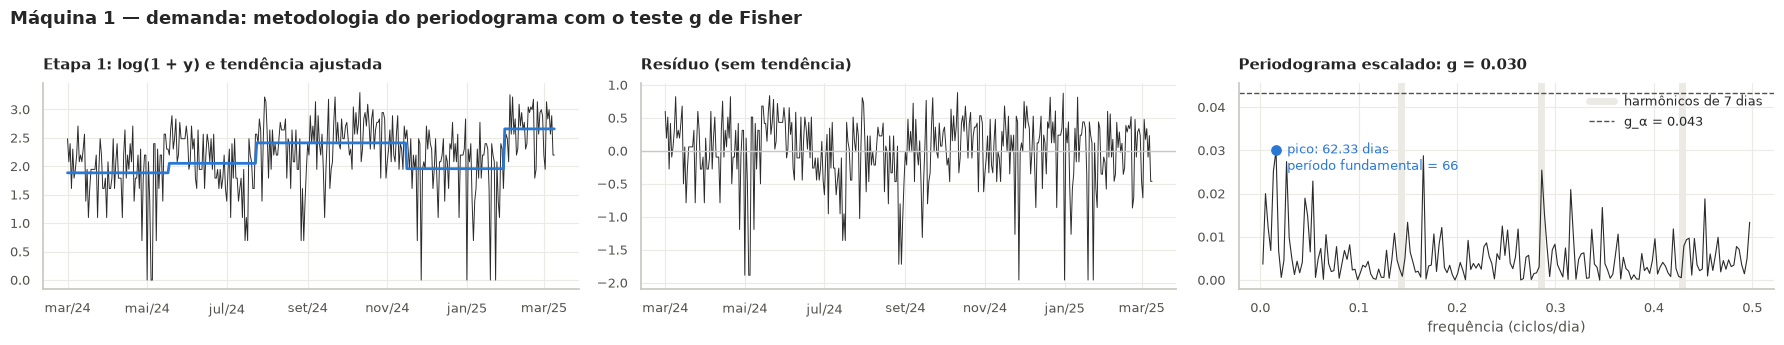

In [9]:
linhas_a, linhas_b = [], []
for s in SERIES:
    for a in ALVOS:
        y = Y[(s, a)]
        ly = pd.Series(np.log1p(y.values.astype(float)), index=y.index)
        nivel = ts.nivel_por_regime(ly, QUEBRAS[s]).values
        ra = ts.metodologia_fisher(y, f"{s} — {a}", tendencia=nivel)
        if (s, a) == ("Máquina 1", "demanda"):
            RES_DEGRAUS = ra
        linhas_a.append({"série": s, "alvo": a, **ra.tabela.iloc[0][["período do pico (dias)", "período fundamental", "g", "g_α", "p-valor", "decisão"]]})
        linhas_b.append({"série": s, "alvo": a, **ts.teste_fisher_banda(ly.values - nivel)})
display(Markdown("**(a) Tendência em degraus, periodograma completo**"))
display(pd.DataFrame(linhas_a).round(4))
display(Markdown("**(b) Faixa de 2 a 31 dias, após retirar os degraus.** A coluna de ranque dá a posição das ordenadas de 7, 3,5 e 2,33 dias (harmônicos 1, 2 e 3 da semana) entre as 174 da faixa."))
display(pd.DataFrame(linhas_b).round(4))
mostrar(ts.grafico_etapas_fisher(RES_DEGRAUS, cor_serie("Máquina 1")))

In [10]:
linhas_c = []
for s in SERIES:
    lim = [Y[(s, "demanda")].index.min()] + sorted(QUEBRAS[s]) + [ORIGEM + pd.Timedelta(days=1)]
    for k in range(len(lim) - 1):
        y = Y[(s, "demanda")].loc[lim[k]:lim[k + 1] - pd.Timedelta(days=1)]
        r = ts.metodologia_fisher(y, f"{s} — regime {k + 1}", grau_inicial=2, grau_iteracoes=2)
        e = r.tabela.iloc[0]
        linhas_c.append({"série": s, "regime": f"{k + 1}: {y.index.min():%d/%m/%y}–{y.index.max():%d/%m/%y}", "dias": len(y),
                         "escala": "log" if r.usar_log else "original", "período do pico": e["período do pico (dias)"],
                         "período fundamental": e["período fundamental"], "g": e["g"], "g_α": e["g_α"], "p-valor": e["p-valor"],
                         "periodicidades retiradas": r.removidos or "—"})
display(Markdown("**(c) Metodologia completa dentro de cada regime (demanda)**"))
display(pd.DataFrame(linhas_c).round(4))

**(c) Metodologia completa dentro de cada regime (demanda)**

,série,regime,dias,escala,período do pico,período fundamental,g,g_α,p-valor,periodicidades retiradas
0,Máquina 1,1: 01/03/24–17/05/24,78,original,3.120,6,0.116,0.164,0.355,—
1,Máquina 1,2: 18/05/24–23/07/24,67,original,2.910,3,0.137,0.183,0.282,—
2,Máquina 1,3: 24/07/24–15/11/24,115,original,4.790,19,0.102,0.118,0.136,—
3,Máquina 1,4: 16/11/24–29/01/25,75,original,2.140,2,0.099,0.168,0.650,—
4,Máquina 1,5: 30/01/25–09/03/25,39,original,2.290,7,0.233,0.281,0.160,—
5,Total,1: 01/03/24–17/05/24,78,original,3.120,6,0.116,0.164,0.355,—
6,Total,2: 18/05/24–23/07/24,67,original,2.910,3,0.137,0.183,0.282,—
7,Total,3: 24/07/24–15/11/24,115,original,4.790,19,0.102,0.118,0.136,—
8,Total,4: 16/11/24–03/02/25,80,original,20.000,20,0.138,0.161,0.136,—
9,Total,5: 04/02/25–09/03/25,34,original,2.270,7,0.198,0.319,0.527,—


**Leitura:**
- **(a) Com a tendência em degraus, nenhuma periodicidade é significativa** (p de 0,26 a 0,53). As baixas frequências encolhem, o que confirma que eram a tendência.
- **(b) Na faixa de 2 a 31 dias, também não há rejeição** (p de 0,15 a 0,37).
  - O harmônico de 3,5 dias está entre as 4 maiores das 174 ordenadas, mas a fundamental de 7 dias fica entre a 106ª e a 170ª.
  - A potência semanal está repartida, e nenhum pico isolado basta.
- **(c) Dentro de cada regime, também nada é significativo.**
  - No regime de 2025, o maior pico é o 3º harmônico da semana (2,3 dias), e o período fundamental identificado é **7**.
  - Mas com 34 a 39 dias (16 a 19 ordenadas), o g de Fisher não tem poder: p = 0,16 na M1 e 0,53 no Total.
- Uma leitura apressada concluiria que **não há sazonalidade semanal**. O teste dirigido da seção 3.4 mostra que isso estaria errado.

### 3.4 Teste do período conhecido: 7 dias

O g de Fisher procura o **maior pico entre todas as frequências**. Ele não usa a informação de que o calendário tem 7 dias. Além disso, um padrão semanal que não é senoidal reparte sua potência entre 3 harmônicos (1/7, 2/7 e 3/7). Quando o período é conhecido a priori, o teste mais poderoso é o **F conjunto das 6 dummies de dia da semana**. Ele equivale a testar a soma do periodograma nos harmônicos de 7.

O teste é feito em cada regime. Dois testes de estabilidade complementam:
- o perfil é o mesmo em todos os regimes? (interação regime × dia);
- o perfil de 2025 difere do perfil comum de 2024?

**Máquina 1 — demanda: F do dia da semana em cada regime**

,regime,dias,F (dia da semana),p,R² do dia da semana,amplitude do perfil (p.p.),dia mais forte,dia mais fraco
0,1: 01/03/24–17/05/24,78,0.966,0.455,0.075,36.358,ter,dom
1,2: 18/05/24–23/07/24,67,0.352,0.906,0.034,29.882,dom,sáb
2,3: 24/07/24–15/11/24,115,0.799,0.572,0.043,34.066,ter,dom
3,4: 16/11/24–29/01/25,75,1.521,0.185,0.118,46.333,sáb,qua
4,5: 30/01/25–09/03/25,39,22.142,0.000,0.806,97.696,seg,dom


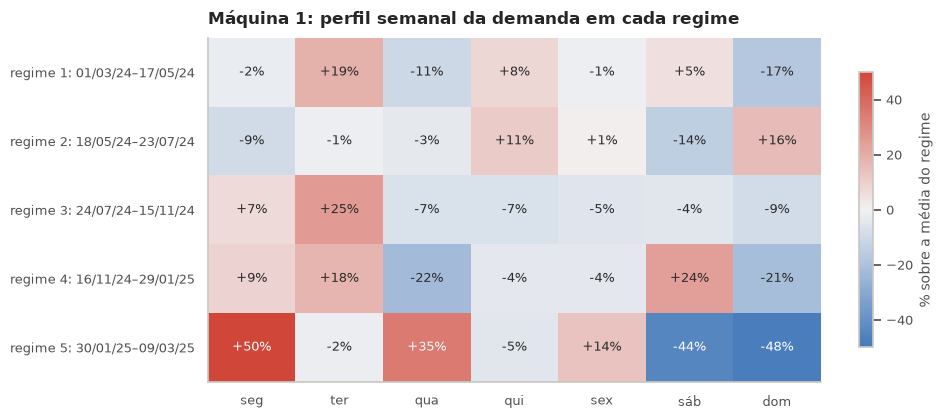

,"F (interação regime × dia, todos)",gl,p (todos),ΔBIC (todos),F (perfil do último regime ≠ anteriores),gl (último),p (último),ΔBIC (último)
estabilidade do perfil,1.247,24.000,0.199,110.544,2.496,6.000,0.022,20.177


**Total — demanda: F do dia da semana em cada regime**

,regime,dias,F (dia da semana),p,R² do dia da semana,amplitude do perfil (p.p.),dia mais forte,dia mais fraco
0,1: 01/03/24–17/05/24,78,0.966,0.455,0.075,36.358,ter,dom
1,2: 18/05/24–23/07/24,67,0.352,0.906,0.034,29.882,dom,sáb
2,3: 24/07/24–15/11/24,115,0.799,0.572,0.043,34.066,ter,dom
3,4: 16/11/24–03/02/25,80,1.745,0.123,0.125,48.689,seg,qua
4,5: 04/02/25–09/03/25,34,4.932,0.002,0.523,65.795,seg,sáb


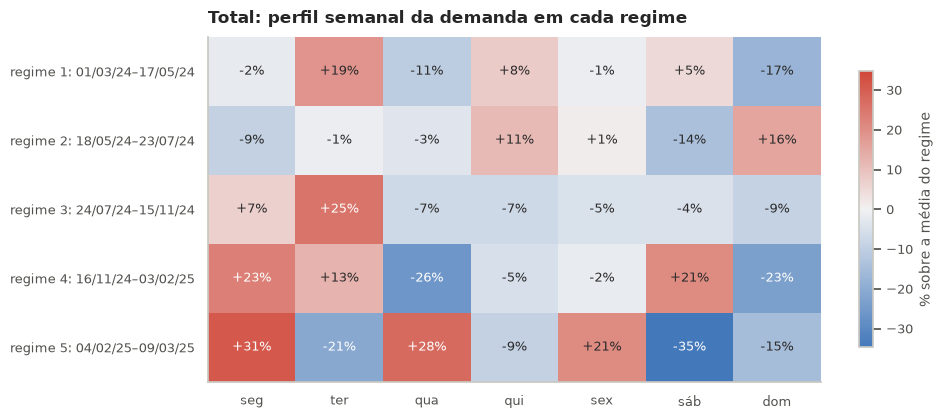

,"F (interação regime × dia, todos)",gl,p (todos),ΔBIC (todos),F (perfil do último regime ≠ anteriores),gl (último),p (último),ΔBIC (último)
estabilidade do perfil,1.008,24.000,0.455,116.395,1.384,6.000,0.220,26.945


In [11]:
for s in SERIES:
    f, perfis, est = ts.teste_sazonalidade_semanal(Y[(s, "demanda")], QUEBRAS[s])
    display(Markdown(f"**{s} — demanda: F do dia da semana em cada regime**"))
    display(f.round(4))
    mostrar(ts.grafico_perfis_semanais(perfis, s))
    display(pd.Series(est, name="estabilidade do perfil").to_frame().T.round(4))

**Leitura:**
- **A sazonalidade semanal só existe no regime de 2025.**
  - **M1:** F = 22 (p < 0,001); entre 30/01 e 09/03/2025, o dia da semana explica **81%** da variância de log(1 + y). O perfil é segunda +50%, quarta +35%, sábado −44% e domingo −48%.
  - **Em 2024**, nenhum regime tem efeito significativo (p de 0,12 a 0,91; R² de 3% a 13%). Os "perfis" mudam de forma a cada regime: o dia mais forte é terça, depois domingo, terça e sábado. É o que se espera de ruído.
  - **Total:** o padrão de 2025 também é significativo (F = 4,9, p = 0,002, R² = 52%), mas mais fraco. A M2 tem perfil próprio e só 34 dias no regime.
- **O perfil de 2025 difere do de 2024 na M1** (F = 2,5 com 6 gl, p = 0,02). O teste global com 24 gl (p = 0,20) dilui o efeito entre os regimes sem padrão, e o BIC penaliza a interação. No Total, a diferença não é significativa (p = 0,22).
- **Leitura de negócio (hipótese):** a nova clientela de 2025 compra em **dias úteis** e esvazia o fim de semana. No notebook 03, 177 dos 196 cartões ativos são novos. O padrão é compatível com um público de escritório ou campus, mas os dados não registram o local. A clientela de 2024 comprava de forma quase uniforme ao longo da semana.
- **Isso explica a seção 3.3.** No ano inteiro, o g de Fisher não vê a semana porque o padrão ocupa só os últimos 10% da amostra e é diluído pelos 335 dias anteriores, sem padrão.
- **Para a modelagem:**
  - estimar a sazonalidade **só com o regime atual**: é por isso que a validação interna escolhe janelas de 8 semanas para HW e SARIMAX, e que o Poisson usa o período desde a última quebra (notebook 06);
  - evitar perfis estimados com o ano inteiro (Fourier fixo, dummies de dia em janelas longas), que subestimam o contraste de 2025;
  - na M1, preferir um perfil **multiplicativo**, ETS(A,N,M), coerente com efeitos em % que crescem com o nível (seção 3.1).

### 3.5 A metodologia de `teste.ipynb` só com os dados de 2025

A seção 3.3 mostrou que, no ano inteiro, o periodograma não enxerga a semana: o padrão ocupa só os últimos ~10% da amostra. `teste.ipynb` contorna isso **cortando a série em 2025**: `DATA_INICIO = "2025-03-01"`, com a sugestão `"2025-02-01"` para incluir fevereiro. Aqui a mesma metodologia (`metodologia_fisher`, sem mudança: log se a amplitude cresce com a média, polinômio de grau 5 e depois 2, g exato de Fisher, período fundamental por AIC) roda em quatro recortes de 2025:
- **01/02/2025**, a opção do `teste.ipynb`;
- **30/01/2025**, a quebra de 2025 detectada no notebook 03;
- **01/01/2025**, o ano-calendário, que ainda inclui o fim do regime anterior;
- **01/03/2025**, o padrão do `teste.ipynb`, com só 23 dias.

Como no `teste.ipynb`, a série vai até o último dia (23/03). A mesma análise só com o treino (até 09/03) entra como sensibilidade. É uma análise descritiva: nenhuma escolha de modelo depende dela.

**Série até 23/03/2025 (como `teste.ipynb`)**

,série,alvo,recorte,fim,dias,escala,pico da 1ª etapa (dias),período fundamental,g,g_α (5%),p-valor,periodicidades encontradas
0,Máquina 1,demanda,desde 01/02/2025 (opção do teste.ipynb),2025-03-23,51,original,7.290,7,0.381,0.228,0.000,7
1,Máquina 1,demanda,desde 30/01/2025 (quebra de 2025),2025-03-23,53,original,7.570,7,0.241,0.221,0.026,7
2,Máquina 1,demanda,desde 01/01/2025 (ano-calendário),2025-03-23,82,original,7.450,7,0.156,0.157,0.052,nenhuma
3,Máquina 1,demanda,desde 01/03/2025 (padrão do teste.ipynb),2025-03-23,23,original,7.670,7,0.344,0.417,0.163,nenhuma
4,Máquina 1,receita,desde 01/02/2025 (opção do teste.ipynb),2025-03-23,51,original,7.290,7,0.362,0.228,0.001,7
5,Máquina 1,receita,desde 30/01/2025 (quebra de 2025),2025-03-23,53,original,7.570,7,0.230,0.221,0.038,7
6,Máquina 1,receita,desde 01/01/2025 (ano-calendário),2025-03-23,82,original,7.450,7,0.142,0.157,0.098,nenhuma
7,Máquina 1,receita,desde 01/03/2025 (padrão do teste.ipynb),2025-03-23,23,original,7.670,7,0.313,0.417,0.256,nenhuma
8,Total,demanda,desde 01/02/2025 (opção do teste.ipynb),2025-03-23,51,original,2.320,7,0.312,0.228,0.003,7
9,Total,demanda,desde 30/01/2025 (quebra de 2025),2025-03-23,53,original,2.300,7,0.268,0.221,0.011,7


**Sensibilidade: só o treino (até 09/03/2025)**

,série,alvo,recorte,fim,dias,escala,pico da 1ª etapa (dias),período fundamental,g,g_α (5%),p-valor,periodicidades encontradas
24,Máquina 1,demanda,desde 01/02/2025 (opção do teste.ipynb),2025-03-09,37,original,7.400,7,0.308,0.293,0.035,7
25,Máquina 1,demanda,desde 30/01/2025 (quebra de 2025),2025-03-09,39,original,2.290,7,0.241,0.281,0.131,nenhuma
26,Máquina 1,demanda,desde 01/01/2025 (ano-calendário),2025-03-09,68,original,6.800,7,0.151,0.183,0.170,nenhuma
27,Máquina 1,receita,desde 01/02/2025 (opção do teste.ipynb),2025-03-09,37,original,2.310,7,0.293,0.293,0.049,7
28,Máquina 1,receita,desde 30/01/2025 (quebra de 2025),2025-03-09,39,original,2.290,7,0.241,0.281,0.131,nenhuma
29,Máquina 1,receita,desde 01/01/2025 (ano-calendário),2025-03-09,68,original,6.800,7,0.146,0.183,0.202,nenhuma
30,Total,demanda,desde 01/02/2025 (opção do teste.ipynb),2025-03-09,37,original,2.310,7,0.379,0.293,0.005,7
31,Total,demanda,desde 30/01/2025 (quebra de 2025),2025-03-09,39,original,2.290,7,0.333,0.281,0.013,"7, 17"
32,Total,demanda,desde 01/01/2025 (ano-calendário),2025-03-09,68,original,2.270,7,0.118,0.183,0.508,nenhuma
33,Total,receita,desde 01/02/2025 (opção do teste.ipynb),2025-03-09,37,original,2.310,7,0.379,0.293,0.005,7


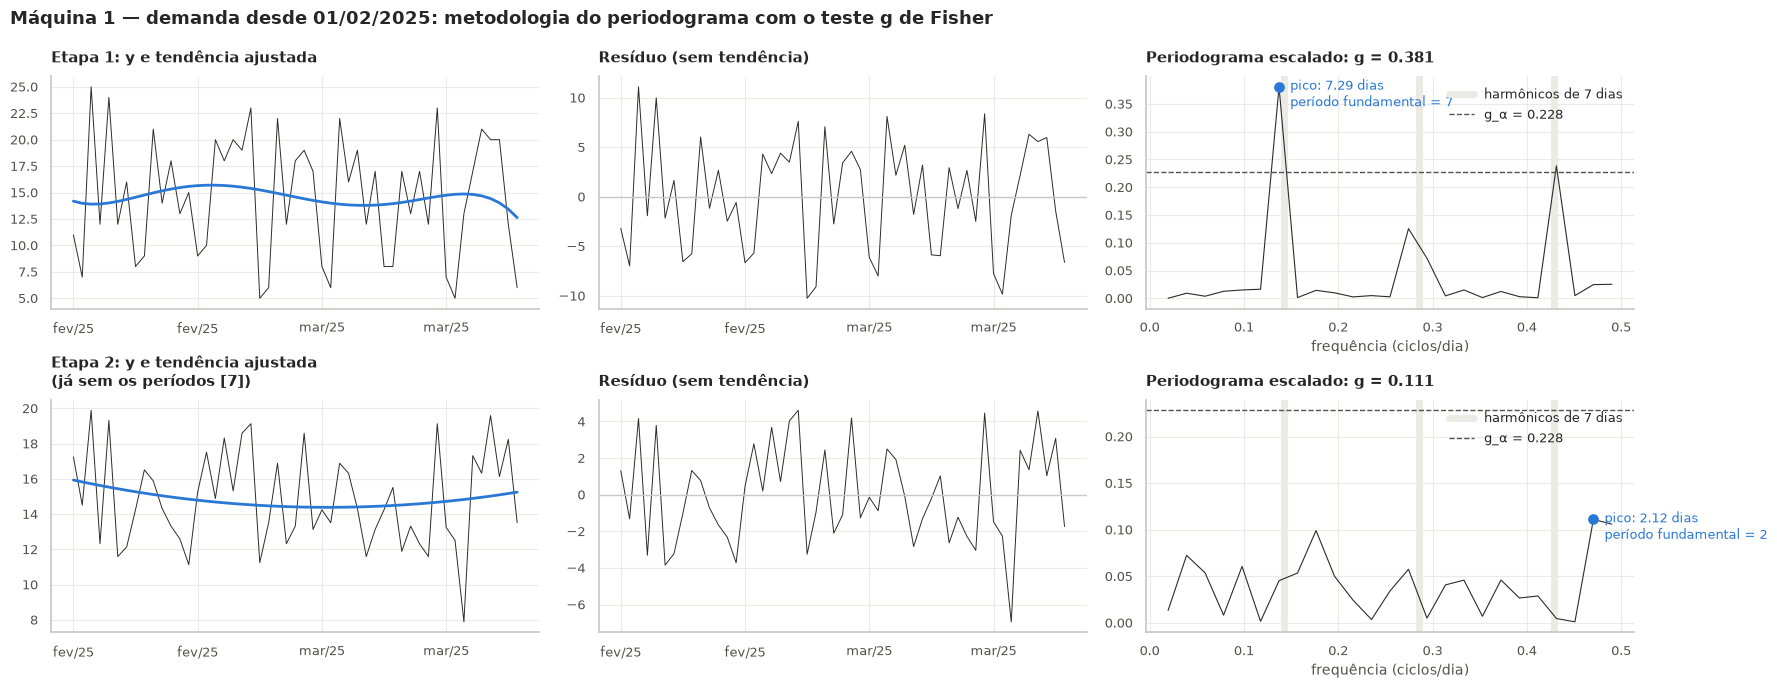

,etapa,tendência,removidos antes,freq. do pico,período do pico (dias),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 5,—,0.137,7.290,1,7,0.381,0.228,0.000,rejeita H0: há componente periódica
1,2,polinômio grau 2,[7],0.471,2.120,1,2,0.111,0.228,0.888,não rejeita H0: sem periodicidade


,seg,ter,qua,qui,sex,sáb,dom
efeito (vendas/dia),5.110,-0.320,4.680,0.410,3.870,-6.240,-7.510


In [12]:
CHAVES_2025 = [(s, a) for s in ("Máquina 1", "Total", "Máquina 2") for a in ALVOS]
FISHER_2025 = ts.fisher_recortes(base.series, CHAVES_2025, fins=(None, ORIGEM))
cols = ["série", "alvo", "recorte", "fim", "dias", "escala", "pico da 1ª etapa (dias)", "período fundamental", "g", "g_α (5%)", "p-valor",
        "periodicidades encontradas"]
display(Markdown("**Série até 23/03/2025 (como `teste.ipynb`)**"))
display(FISHER_2025[FISHER_2025["fim"] == base.fim][cols].round(4))
display(Markdown("**Sensibilidade: só o treino (até 09/03/2025)**"))
display(FISHER_2025[FISHER_2025["fim"] == ORIGEM][cols].round(4))

RES_M1_2025 = ts.metodologia_fisher(base.series[("Máquina 1", "demanda")].loc["2025-02-01":], "Máquina 1 — demanda desde 01/02/2025")
mostrar(ts.grafico_etapas_fisher(RES_M1_2025, cor_serie("Máquina 1")))
display(RES_M1_2025.tabela.round(4))
display(ts.perfil_semanal_fisher(RES_M1_2025).round(2).to_frame().T)

**Leitura:**
- **Só com os dados do regime de 2025, a metodologia de `teste.ipynb` encontra período 7.**
  - **Máquina 1, desde 01/02/2025:** pico em 7,3 dias, período fundamental 7, g = 0,38 contra g_α = 0,23 (**p = 0,0003**). Depois de retirar a semana, nada mais é significativo (p = 0,89). A receita repete o resultado (p = 0,0005).
  - **Total:** o pico está no 3º harmônico (2,3 dias), mas o período fundamental é 7 (p = 0,003).
- **O perfil retirado é o padrão de dias úteis da seção 3.4:** segunda +5,1, quarta +4,7 e sexta +3,9 vendas/dia; sábado −6,2 e domingo −7,5.
- **O resultado depende de o recorte ficar dentro do regime:**
  - desde a quebra (30/01), ainda é significativo (M1 p = 0,03; Total p = 0,01);
  - **incluindo janeiro (01/01)**, fica limítrofe na M1 (p = 0,05) e some no Total. Janeiro pertence ao regime anterior, e o salto de nível volta a contaminar o resíduo, como na seção 3.3;
  - **só março (23 dias)** não tem poder: o pico continua em 7,7 dias, mas p = 0,16. Com 3 semanas, o periodograma tem só 11 ordenadas.
- **Só com o treino (até 09/03), desde 01/02,** o período 7 continua significativo (M1 p = 0,03; Total p = 0,006).
- **Máquina 2:** sem período 7 em nenhum recorte. O "período 10" de março (23 dias, ~2 ciclos) não é interpretável: amostra mínima e vários recortes testados.
- **Conclusão:** a sazonalidade semanal é real, mas **é do regime de 2025**. O `teste.ipynb` a encontra porque começa em 2025; no ano inteiro, ela é diluída pelos degraus. Isso reforça as decisões da seção 3.4: período 7, estimado só com as últimas semanas.

## 4. Ciclo

Ciclo é uma oscilação **mais longa que a sazonalidade e sem período fixo**. Para não confundir ciclo com degraus, o procedimento é:
1. dessazonalizar log(1 + y) pela STL;
2. agregar por semana completa;
3. **subtrair o nível do regime**, obtendo o desvio (ciclo + ruído);
4. suavizar o desvio pelo filtro HP.

O λ do HP é escolhido pelo período de corte: λ = 1/[4(1 − cos(2π/P))²], com P = 13 semanas, o que dá λ ≈ 19. A parte suave retém movimentos de um trimestre ou mais. A regra de Ravn-Uhlig para dados semanais (λ ≈ 4,6 × 10⁷) mira ciclos de negócios de anos e, com 53 semanas, só produziria uma reta.

**Testes formais:**
- Ljung-Box no desvio semanal: o desvio é ruído branco?
- g de Fisher no desvio semanal: há um ciclo **regular**?
- Kruskal-Wallis entre os terços do mês: há um ciclo mensal (salário, início do mês)?

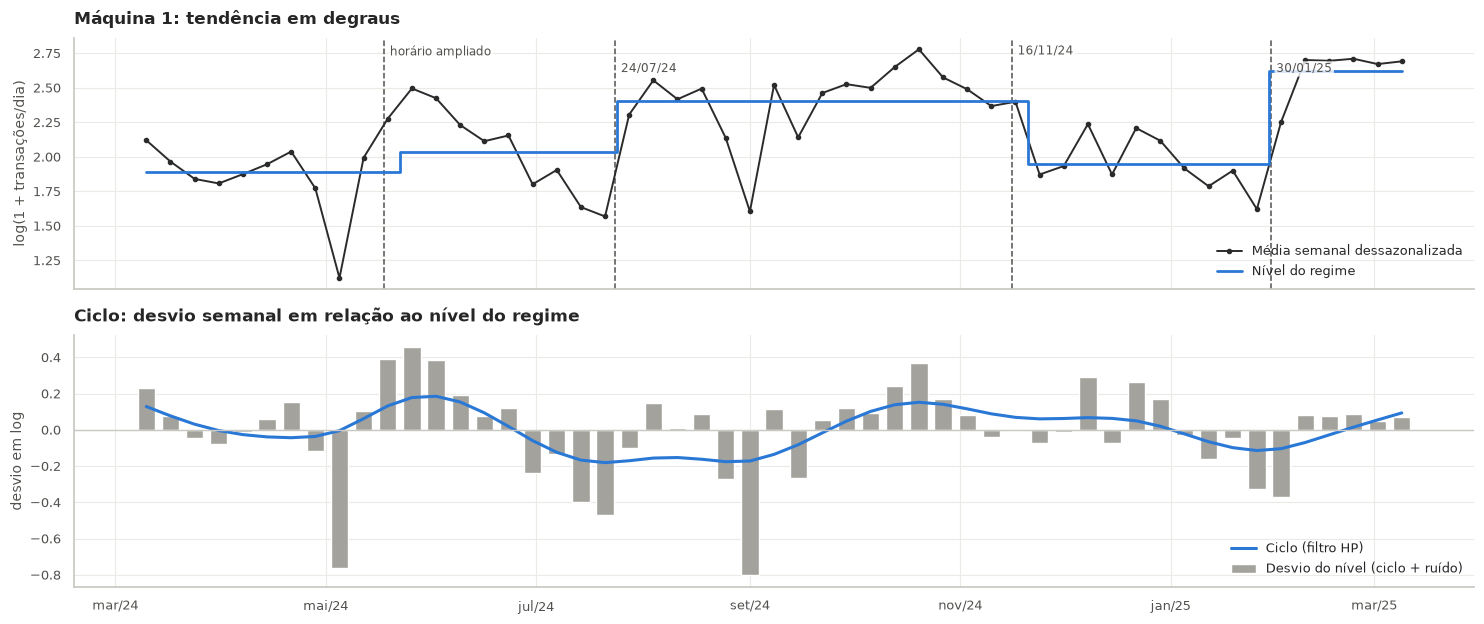

**Máquina 1 — resumo do ciclo**

,semanas,Ljung-Box p do desvio (4 / 8 / 13 semanas),"amplitude do ciclo (% do nível, ±)",desvio-padrão do ciclo (%),fração da variância do desvio explicada pelo ciclo,duração média de um ciclo completo (semanas),trocas de sinal
valor,53,0.02 / 0.04 / 0.02,20.375,11.268,0.179,18.800,6


Teste g de Fisher no desvio semanal (períodos em semanas):

,etapa,tendência,removidos antes,freq. do pico,período do pico (semanas),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 0,—,0.094,10.600,2,19,0.154,0.221,0.368,não rejeita H0: sem periodicidade


Ciclo mensal: Kruskal-Wallis H = 2.89, p = 0.236

,dias,efeito (% sobre o nível)
dias 1–10,129,-3.210
dias 11–20,120,4.980
dias 21–31,125,-1.290


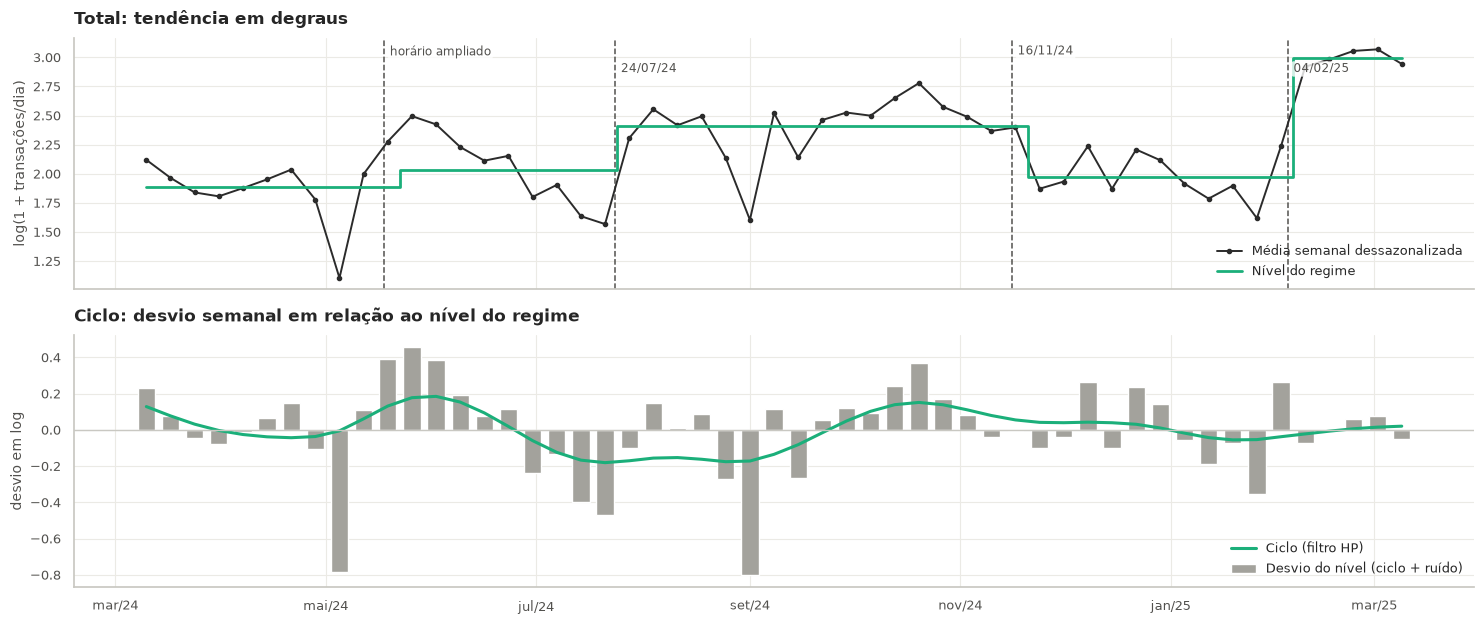

**Total — resumo do ciclo**

,semanas,Ljung-Box p do desvio (4 / 8 / 13 semanas),"amplitude do ciclo (% do nível, ±)",desvio-padrão do ciclo (%),fração da variância do desvio explicada pelo ciclo,duração média de um ciclo completo (semanas),trocas de sinal
valor,53,0.06 / 0.11 / 0.06,20.339,10.629,0.162,18.800,6


Teste g de Fisher no desvio semanal (períodos em semanas):

,etapa,tendência,removidos antes,freq. do pico,período do pico (semanas),harmônico,período fundamental,g,g_α,p-valor,decisão
0,1,polinômio grau 0,—,0.113,8.830,2,19,0.154,0.221,0.368,não rejeita H0: sem periodicidade


Ciclo mensal: Kruskal-Wallis H = 2.38, p = 0.304

,dias,efeito (% sobre o nível)
dias 1–10,129,-3.040
dias 11–20,120,4.390
dias 21–31,125,-0.930


In [13]:
for s in SERIES:
    c = ts.componente_ciclo(Y[(s, "demanda")], QUEBRAS[s])
    mostrar(ts.grafico_ciclo(c, ROTULOS[s], s))
    rf = ts.metodologia_fisher(c["desvio"], f"{s} — desvio semanal", grau_inicial=0, grau_iteracoes=0,
                               decidir_log=False, unidade_tempo="semanas", janela_amp=4)
    dm = ts.efeito_dia_do_mes(Y[(s, "demanda")], QUEBRAS[s])
    display(Markdown(f"**{s} — resumo do ciclo**"))
    display(pd.Series(ts.resumo_ciclo(c)).to_frame("valor").T)
    display(Markdown("Teste g de Fisher no desvio semanal (períodos em semanas):"))
    display(rf.tabela.round(4))
    display(Markdown(f"Ciclo mensal: Kruskal-Wallis H = {dm.attrs['H de Kruskal-Wallis']:.2f}, p = {dm.attrs['p']:.3f}"))
    display(dm.round(2))

**Leitura:**
- **O que sobra é um desvio, não um ciclo regular.** Retirados os degraus e a semana, sobra um desvio semanal de até ±20% em torno do nível do regime. O "ciclo" HP troca de sinal 6 vezes em 53 semanas (≈ 19 semanas por ciclo completo) e explica 16% a 18% da variância do desvio.
- **O ciclo não é regular.** O g de Fisher no desvio semanal não rejeita H0 (p = 0,37 nas duas séries): não há período dominante, nem mensal (4–5 semanas) nem trimestral.
- **Mas há persistência.**
  - Na M1, o Ljung-Box rejeita que o desvio seja ruído branco (p de 0,02 a 0,04); no Total, fica na fronteira (p de 0,06 a 0,11). Semanas boas e ruins vêm em sequência.
  - Causas prováveis: movimentos de nível menores que o segmento mínimo de 28 dias do detector de quebras, como a queda de jun–jul/2024 dentro do regime 2, e eventos não registrados.
- **Não há ciclo mensal de pagamento.** Os terços do mês diferem de −3% a +5%, sem significância (Kruskal-Wallis p = 0,24 e 0,30).
- **Para a modelagem:**
  - não há ciclo determinístico a modelar. A persistência de curto prazo é absorvida pelo nível adaptativo (suavização exponencial, MA(1) após Δ1) e pelas médias móveis de 7–30 dias da Random Forest;
  - `inicio_mes` não tem suporte como ciclo. Ele entra no SARIMAX do Total só por seleção de AICc, e seu coeficiente deve ser lido com cautela.

## 5. ACF e PACF antes e depois de remover a tendência pela diferença

**O que observar:**
- **Série original.** Uma ACF que decai **devagar** indica nível não estacionário: tendência ou degraus.
- **Δ1 = y_t − y_{t−1}** remove a tendência estocástica. Se a ACF de Δ1 tem um único pico negativo perto de −0,5 na defasagem 1 e a PACF decai em sinais negativos, a assinatura é a de um **MA(1) com θ próximo de −1**. Isso indica diferenciação excessiva, ou nível que só muda ocasionalmente (modelo de nível local, equivalente à suavização exponencial).
- **Δ7** remove o padrão semanal fixo, e **Δ1Δ7** remove os dois. Um pico negativo forte na defasagem 7 após Δ7 indica que a diferença sazonal é excessiva, e que a sazonalidade é determinística ou fraca.

Nas figuras, as faixas cinzas marcam as defasagens múltiplas de 7, e a área sombreada é o intervalo de 95% sob H0.

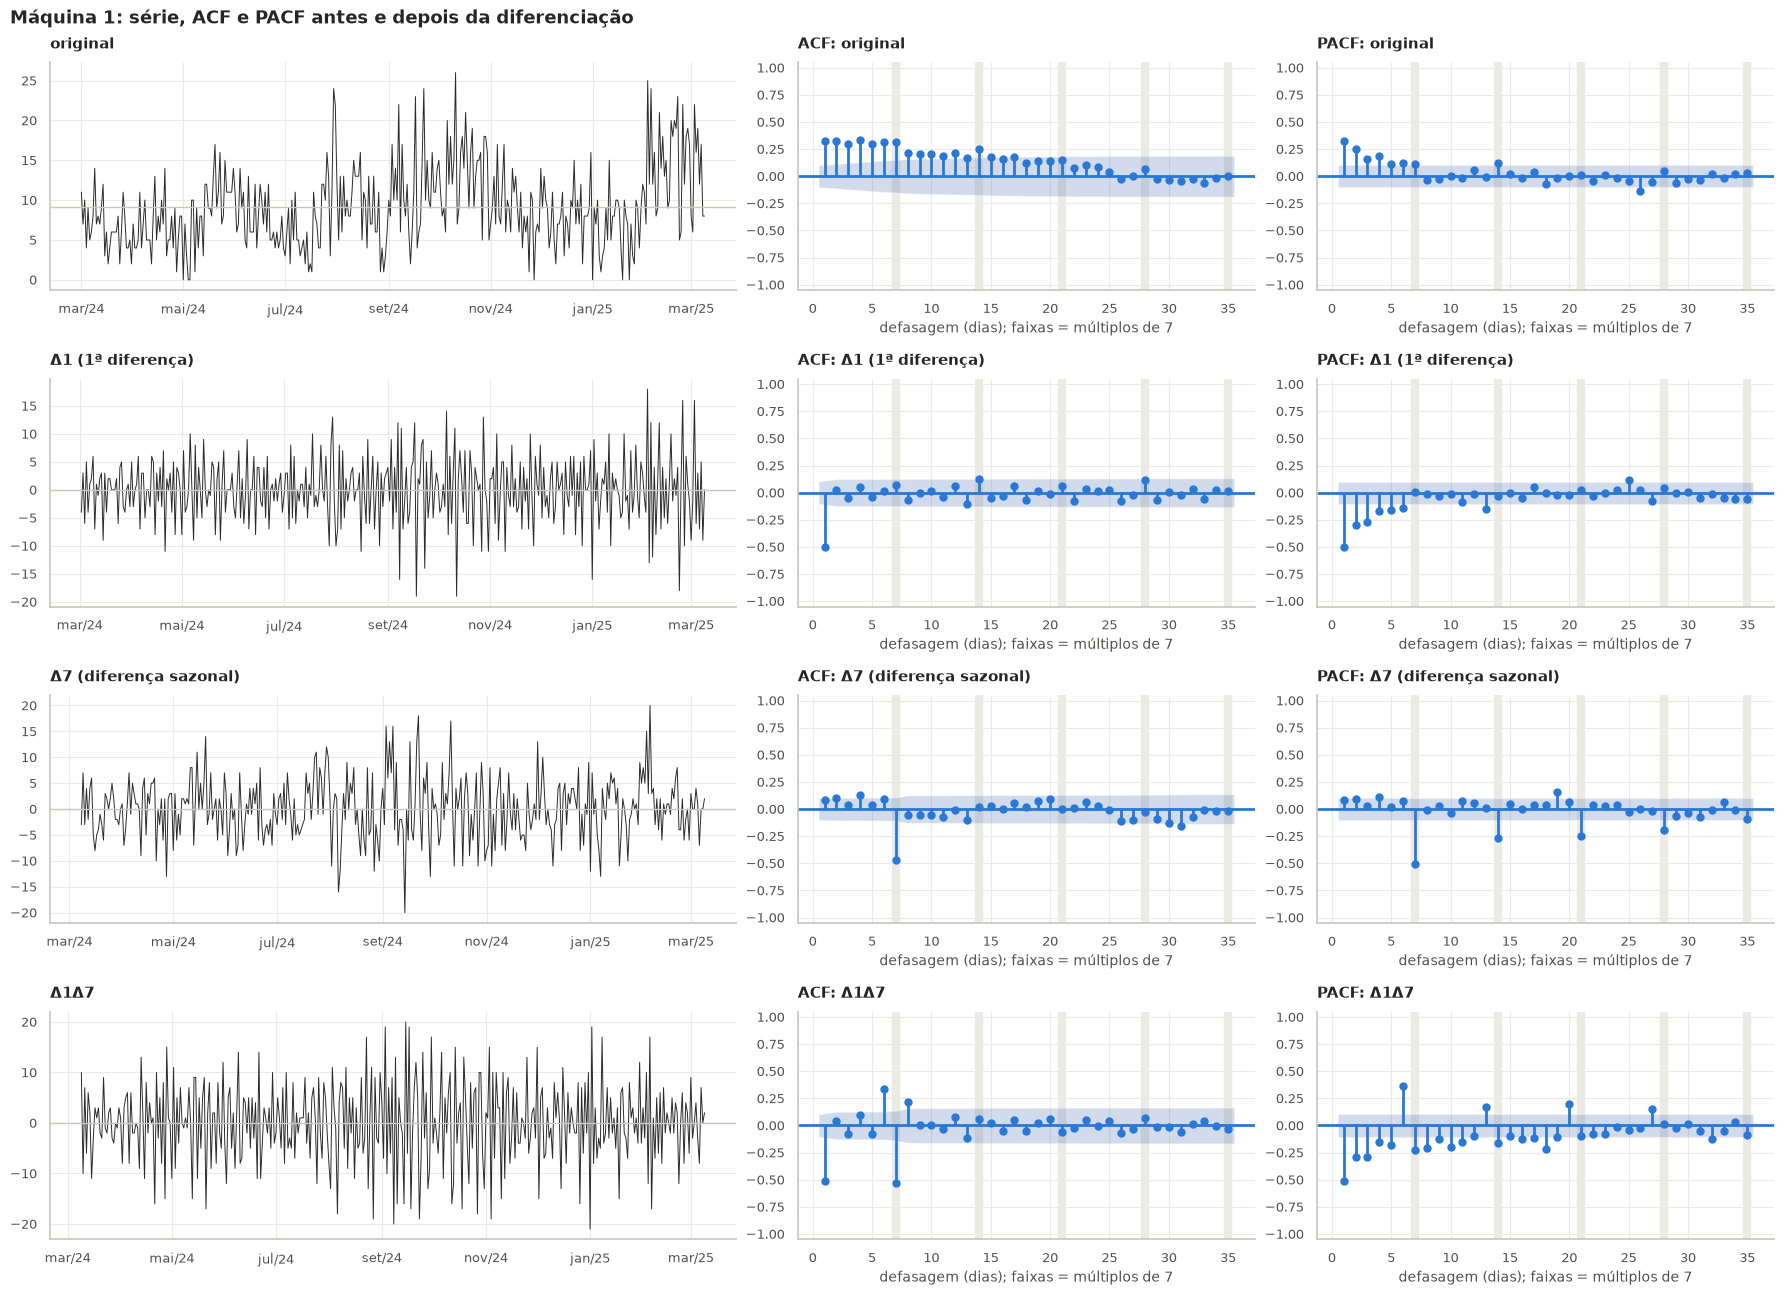

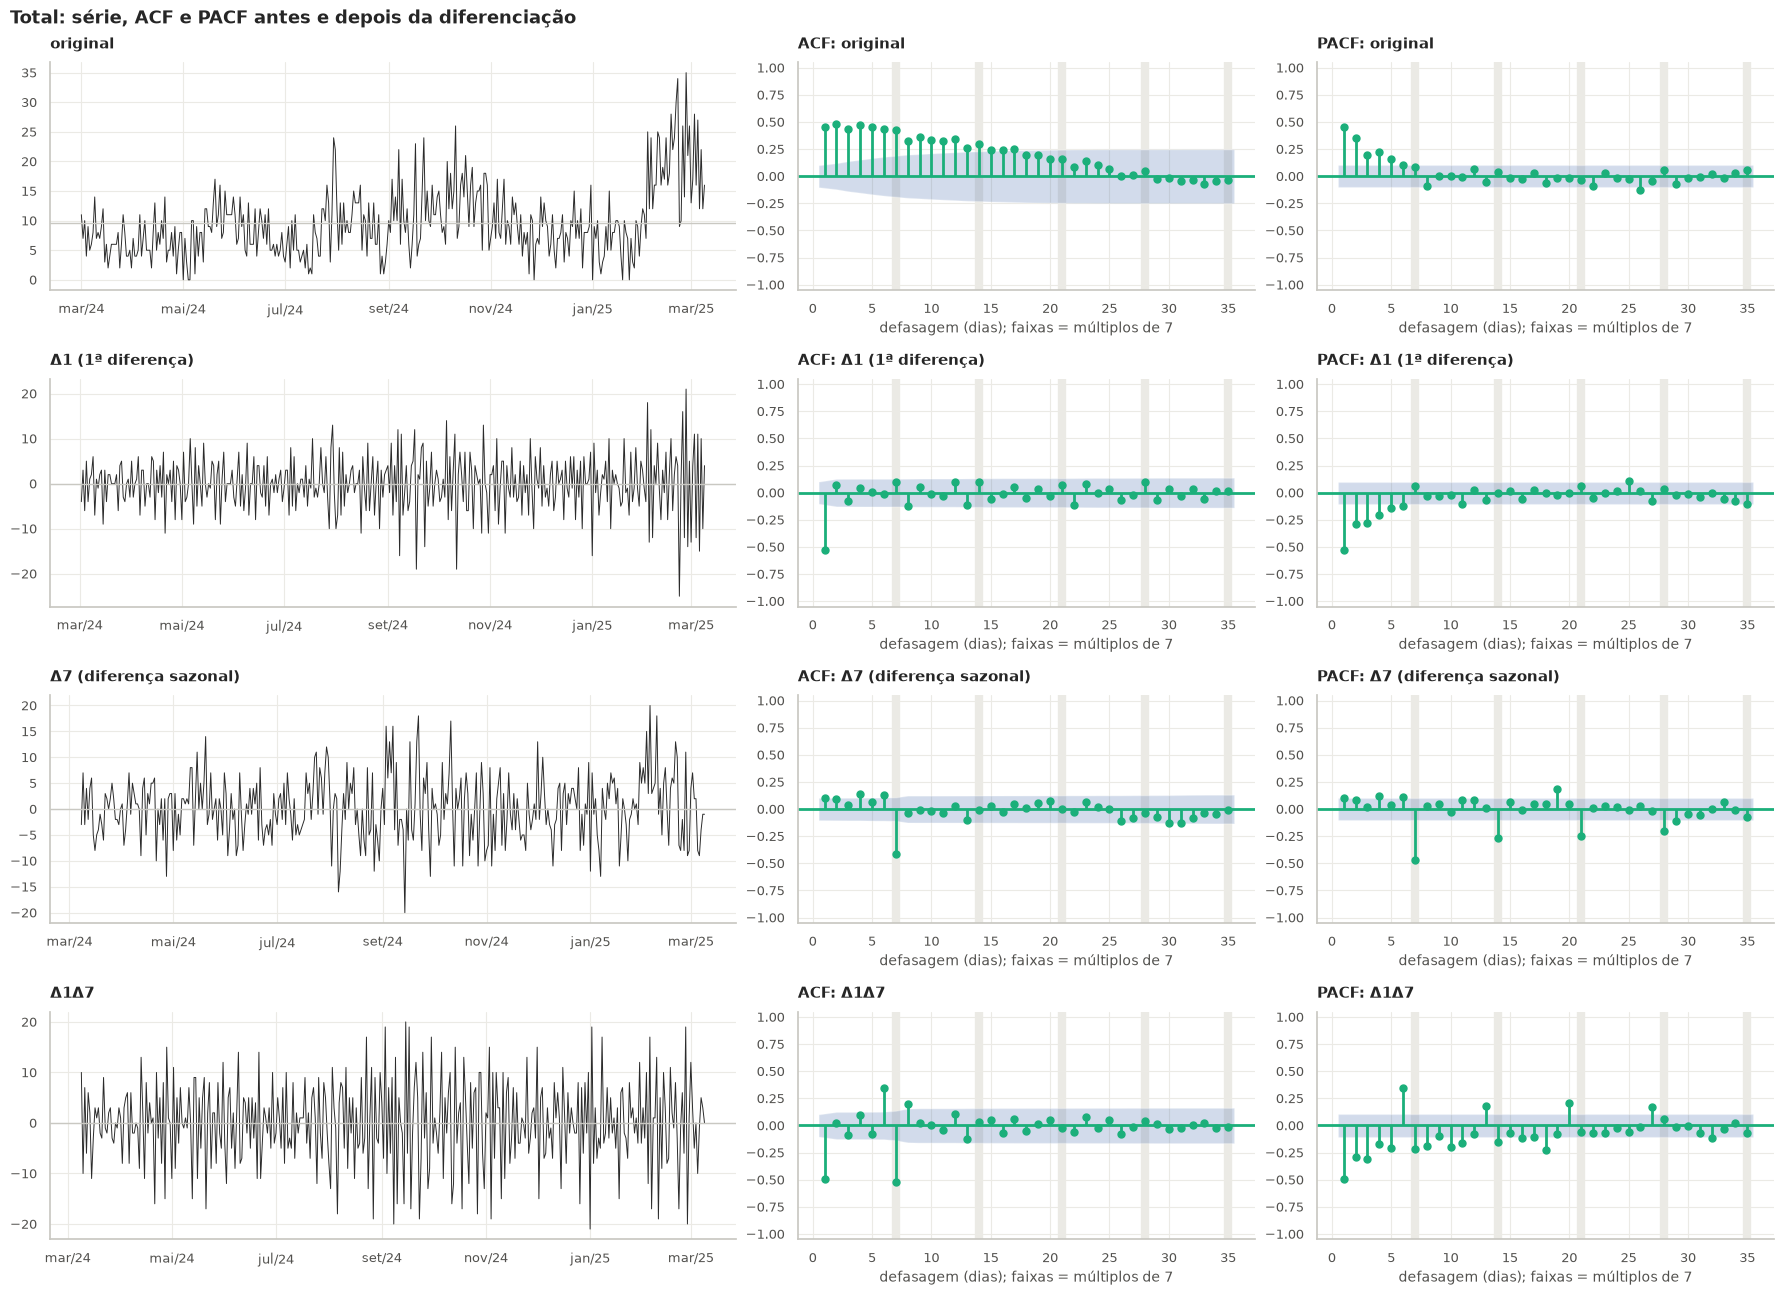

In [14]:
for s in SERIES:
    mostrar(ts.grafico_acf_pacf(Y[(s, "demanda")], s))

In [15]:
for s in SERIES:
    display(Markdown(f"**{s} — demanda: ACF e PACF em defasagens selecionadas**"))
    display(ts.tabela_acf_pacf(Y[(s, "demanda")], quebras=QUEBRAS[s]).round(3))

**Máquina 1 — demanda: ACF e PACF em defasagens selecionadas**

,transformação,função,lag 1,lag 2,lag 3,lag 6,lag 7,lag 8,lag 14,lag 21,lag 28,banda ±
0,original,ACF,0.329,0.329,0.297,0.312,0.313,0.216,0.254,0.151,0.063,0.101
1,original,PACF,0.329,0.248,0.161,0.118,0.110,-0.034,0.125,0.007,0.052,0.101
2,Δ1 (1ª diferença),ACF,-0.500,0.024,-0.050,0.011,0.072,-0.065,0.125,0.063,0.113,0.101
3,Δ1 (1ª diferença),PACF,-0.500,-0.301,-0.271,-0.140,0.005,-0.012,-0.032,0.028,0.039,0.101
4,Δ7 (diferença sazonal),ACF,0.083,0.100,0.040,0.096,-0.466,-0.057,0.022,-0.002,-0.028,0.102
5,Δ7 (diferença sazonal),PACF,0.083,0.094,0.025,0.072,-0.506,-0.006,-0.264,-0.244,-0.196,0.102
6,Δ1Δ7,ACF,-0.508,0.041,-0.078,0.338,-0.531,0.221,0.062,-0.061,0.071,0.102
7,Δ1Δ7,PACF,-0.508,-0.293,-0.295,0.364,-0.222,-0.207,-0.158,-0.093,0.010,0.102
8,sem degraus (y − nível do regime),ACF,0.080,0.082,0.044,0.094,0.139,0.015,0.133,0.058,0.030,0.101
9,sem degraus (y − nível do regime),PACF,0.080,0.076,0.033,0.072,0.118,-0.023,0.122,0.023,0.030,0.101


**Total — demanda: ACF e PACF em defasagens selecionadas**

,transformação,função,lag 1,lag 2,lag 3,lag 6,lag 7,lag 8,lag 14,lag 21,lag 28,banda ±
0,original,ACF,0.449,0.481,0.433,0.437,0.430,0.324,0.296,0.162,0.047,0.101
1,original,PACF,0.449,0.350,0.193,0.100,0.086,-0.092,0.039,-0.032,0.054,0.101
2,Δ1 (1ª diferença),ACF,-0.528,0.068,-0.075,-0.017,0.095,-0.126,0.095,0.071,0.099,0.101
3,Δ1 (1ª diferença),PACF,-0.528,-0.293,-0.278,-0.125,0.057,-0.026,-0.001,0.059,0.034,0.101
4,Δ7 (diferença sazonal),ACF,0.100,0.089,0.036,0.133,-0.416,-0.038,-0.005,0.003,-0.039,0.102
5,Δ7 (diferença sazonal),PACF,0.100,0.080,0.020,0.108,-0.469,0.026,-0.264,-0.249,-0.204,0.102
6,Δ1Δ7,ACF,-0.493,0.022,-0.084,0.346,-0.517,0.194,0.034,-0.026,0.046,0.102
7,Δ1Δ7,PACF,-0.493,-0.292,-0.309,0.346,-0.213,-0.191,-0.154,-0.062,0.058,0.102
8,sem degraus (y − nível do regime),ACF,0.038,0.109,0.033,0.076,0.110,-0.057,0.070,0.037,0.014,0.101
9,sem degraus (y − nível do regime),PACF,0.038,0.108,0.025,0.054,0.089,-0.087,0.058,0.002,0.042,0.101


### 5.1 Testes de raiz unitária e de estacionariedade

As hipóteses dos testes são opostas:
- **ADF**: H0 = raiz unitária;
- **KPSS**: H0 = estacionária.

"Estacionária" exige que o ADF rejeite e o KPSS não. A tabela inclui a alternativa à diferença, **retirar os degraus**: se y − nível do regime já é estacionária, a série é estacionária em torno de quebras, e não um passeio aleatório. Em séries com mudança de nível, o ADF perde poder (Perron, 1989). O **Zivot-Andrews** permite uma quebra endógena no intercepto, mas só uma.

In [16]:
est = pd.concat([ts.testes_estacionariedade(Y[(s, a)], f"{s} — {a}", QUEBRAS[s]) for s in SERIES for a in ALVOS])
display(est.round(4).reset_index(drop=True))

,série,transformação,n,ADF estat.,ADF p,KPSS estat.,KPSS p,Ljung-Box p (7),Ljung-Box p (14),diagnóstico,Zivot-Andrews estat.,Zivot-Andrews p,quebra ZA
0,Máquina 1 — demanda,original,374,-3.268,0.016,0.848,0.010,0.000,0.000,inconclusivo (testes divergem),-4.531,0.110,2024-10-30
1,Máquina 1 — demanda,Δ1 (1ª diferença),373,-13.418,0.000,0.095,0.100,0.000,0.000,estacionária,NaN,NaN,NaT
2,Máquina 1 — demanda,Δ7 (diferença sazonal),367,-6.789,0.000,0.034,0.100,0.000,0.000,estacionária,NaN,NaN,NaT
3,Máquina 1 — demanda,Δ1Δ7,366,-9.678,0.000,0.069,0.100,0.000,0.000,estacionária,NaN,NaN,NaT
4,Máquina 1 — demanda,sem degraus (y − nível do regime),374,-5.091,0.000,0.094,0.100,0.003,0.007,estacionária,NaN,NaN,NaT
5,Máquina 1 — demanda,"sem degraus, Δ1",373,-8.999,0.000,0.114,0.100,0.000,0.000,estacionária,NaN,NaN,NaT
6,Máquina 1 — receita,original,374,-3.254,0.017,0.695,0.014,0.000,0.000,inconclusivo (testes divergem),-4.188,0.245,2024-10-30
7,Máquina 1 — receita,Δ1 (1ª diferença),373,-13.579,0.000,0.109,0.100,0.000,0.000,estacionária,NaN,NaN,NaT
8,Máquina 1 — receita,Δ7 (diferença sazonal),367,-6.775,0.000,0.039,0.100,0.000,0.000,estacionária,NaN,NaN,NaT
9,Máquina 1 — receita,Δ1Δ7,366,-9.605,0.000,0.095,0.100,0.000,0.000,estacionária,NaN,NaN,NaT


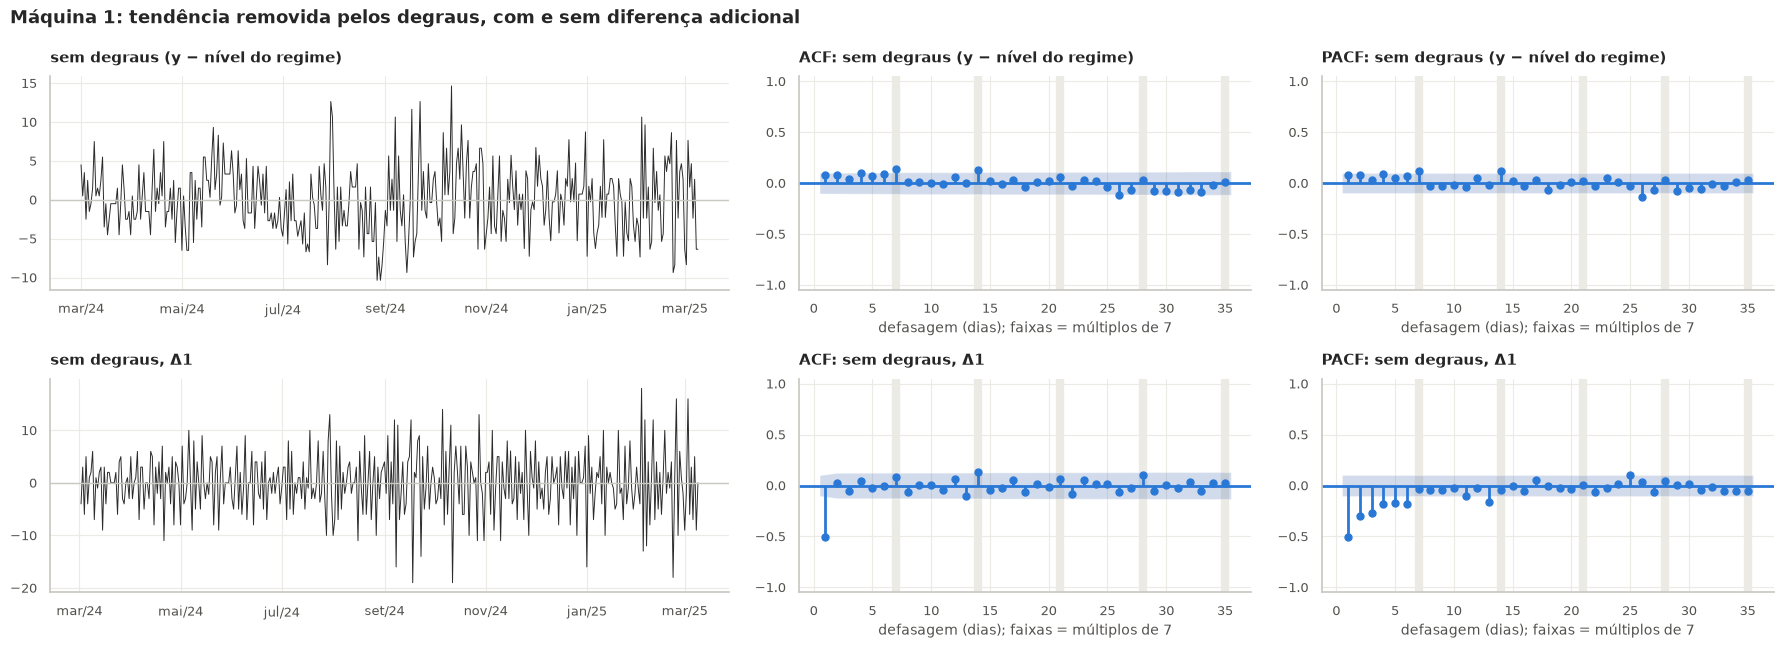

In [17]:
mostrar(ts.grafico_acf_pacf(Y[("Máquina 1", "demanda")], "Máquina 1", quebras=QUEBRAS["Máquina 1"],
                            transformacoes=("sem degraus (y − nível do regime)", "sem degraus, Δ1"),
                            titulo="Máquina 1: tendência removida pelos degraus, com e sem diferença adicional"))

In [18]:
# Ordens que a seleção automática do pipeline escolheu (notebook 06), para conferir a coerência com a ACF/PACF
try:
    from src.pipeline import carregar_artefato
    R = {(r.modelo, r.serie, r.alvo): r for r in carregar_artefato("resultados_principal")["resultados"]}
    display(pd.DataFrame([{"modelo": m, "série": s, "alvo": "demanda", "especificação escolhida": R[(m, s, "demanda")].especificacao}
                          for m in ["SARIMAX", "Holt-Winters"] for s in SERIES]))
except FileNotFoundError:
    print("Artefatos do pipeline ausentes: rode `python -m src.pipeline --etapas modelagem`.")

,modelo,série,alvo,especificação escolhida
0,SARIMAX,Máquina 1,demanda,"SARIMA(0,1,1)(1,0,1)[7] + [data_comercial, dum..."
1,SARIMAX,Total,demanda,"SARIMA(0,1,1)(1,0,0)[7] + [maquinas_ativas, da..."
2,Holt-Winters,Máquina 1,demanda,"ETS(A,N,M) · últimas 8 semanas · raiz (Anscombe)"
3,Holt-Winters,Total,demanda,"ETS(A,N,A) · últimas 8 semanas · nenhuma"


**Leitura:**
- **Série original.** A ACF fica em ≈ 0,30 (M1) e ≈ 0,45 (Total) nas defasagens 1 a 7 e decai devagar até ≈ 25 dias. Não há picos destacados em 7, 14 e 21. É a assinatura de **nível que muda** (degraus), não de sazonalidade forte. A PACF tem 3–4 defasagens iniciais significativas, como se espera de uma média local persistente.
- **Δ1, a tendência removida pela diferença.**
  - A ACF se reduz a um **único pico** na defasagem 1: −0,50 na M1 e −0,53 no Total. O resto fica na banda, com excessos isolados de |ρ| ≤ 0,13.
  - A PACF decai em valores negativos (−0,50, −0,30, −0,27, …).
  - É a assinatura clássica de um **MA(1) com θ próximo de −1**: um ARIMA(0,1,1), equivalente à suavização exponencial simples, com nível que se ajusta devagar sobre ruído branco.
- **O −0,5 na defasagem 1 também denuncia diferenciação excessiva.** A linha "sem degraus" mostra:
  - y − nível do regime já é estacionária (ADF p < 0,001; KPSS p ≥ 0,10), com ACF ≤ 0,14 em todas as defasagens;
  - diferenciá-la de novo recria o pico de −0,50.
- **A série é estacionária em torno de quebras**, e não um passeio aleatório.
  - Na série original, ADF e KPSS divergem na M1, e o Total aparece como não estacionário: é o viés de Perron.
  - O Zivot-Andrews, que admite uma única quebra, também não rejeita (p = 0,11 e 0,58), porque há quatro.
- **Δ7 é diferenciação sazonal excessiva.** Gera um pico de −0,47 na defasagem 7 da ACF, e a PACF decai em 7, 14, 21 e 28. Δ1Δ7 sobrepõe as duas assinaturas, com picos em 1, 6, 7 e 8. **Não se deve usar D = 1.**
- **Coerência com a seleção automática (notebook 06):**
  - o auto_arima escolheu **SARIMA(0,1,1)(1,0,1)₇** na M1 e **(0,1,1)(1,0,0)₇** no Total, na janela de 8 semanas: d = 1 com MA(1), D = 0 e termos sazonais AR/MA leves, exatamente o que a ACF/PACF indica. Os degraus restantes entram como `dummy_novos_clientes` e `maquinas_ativas`;
  - o Holt-Winters escolhido é ETS(·,N,·), sem tendência, coerente com a seção 2.
- **As duas formas de remover a tendência são válidas, e o projeto usa as duas:**
  - **diferença + MA(1)** (SARIMAX, HW) se adapta a quebras ainda não detectadas;
  - **degraus explícitos** (dummies, Poisson desde a última quebra) dão efeitos interpretáveis, mas dependem de detectar a quebra a tempo, com 3 a 4 semanas de atraso (notebook 04).

## 6. Síntese e implicações para a modelagem

| Pergunta | Evidência | Decisão (notebook 06) |
|---|---|---|
| Tendência? | Mann-Kendall significativo só no ano inteiro; em 4 de 5 regimes, não; degraus vencem a reta por ΔBIC de 49 a 70 | sem tendência linear; ETS sem tendência; dummies de regime; janelas curtas |
| Sazonalidade? | periodograma direto: picos espúrios de 62 a 187 dias, resíduo dos degraus; com degraus ou na faixa de 2 a 31 dias, nada significativo; F do dia da semana significativo só em 2025 (R² de 81% na M1); a metodologia de `teste.ipynb` só com 2025 acha período 7 (M1 p = 0,0003 desde 01/02) | período 7, estimado só no regime atual (8 semanas); perfil multiplicativo na M1 |
| Ciclo? | desvio semanal persistente (Ljung-Box p ≈ 0,02 na M1), sem período (Fisher p = 0,37) e sem efeito do dia do mês | nada determinístico; o nível adaptativo e as médias móveis absorvem a persistência |
| ACF/PACF e estacionariedade? | estacionária em torno dos degraus; Δ1 deixa um MA(1) com θ ≈ −1; Δ7 é excessiva | SARIMA(0,1,1)(P,0,Q)₇, ou d = 0 com dummies; nunca D = 1 |

**Sobre a metodologia de `teste.ipynb`:** o teste g de Fisher é válido e foi aplicado como especificado. Mas ele supõe que a tendência foi bem removida. Em séries com quebras estruturais, a tendência polinomial deixa resíduos de baixa frequência, que o teste confunde com periodicidade. Duas adaptações resolvem o problema:
1. **tendência em degraus**, nas datas detectadas no notebook 03;
2. um **teste dirigido para o período que o calendário já informa** (7 dias), mais poderoso que a busca pelo maior pico.